# Investment Research Agent

## 1. Abstract

An autonomous agent applied to financial research depends as much on the
reliability of its data sources as on the reasoning applied to what those
sources return. This notebook presents an **Investment Research Agent** that,
given a stock symbol, plans its own research steps, retrieves market and news
data through registered tools, analyses that material through three specialist
components, and evaluates and refines its own report before returning it. The
system is built as three LangGraph workflows implementing the prompt-chaining,
routing and evaluator–optimiser patterns, and exercises four agent functions:
planning, dynamic tool use, self-reflection, and learning across runs through
brief per-symbol notes that inform subsequent planning. All market and news
data is drawn from Yahoo Finance, and language-model responses are validated
against a schema wherever a result controls program flow.

Repeated evaluation established that a quality score produced by a language
model is not by itself a sufficient criterion for accepting a report. Reports
whose news section contained no source material scored between 0.95 and 0.99
and were accepted, because criteria that reward candour about missing
information are satisfied more readily by an empty report than by a
substantive one; scores rose as content fell. An input-coverage check, applied
in code and held separate from the scores, was therefore introduced, and
rejects a report scoring 1.00 on every criterion when no articles were
ingested. A comparable defect upstream returned unreported future earnings
quarters without raising an error, and was detectable only by comparison
against the source data rather than from the report it produced.

The resulting agent produces grounded, sectioned reports that state their own
limitations and withhold investment advice. A draft deliberately corrupted
with invented figures and a buy recommendation is rejected at 0.55 grounding
and repaired to 1.00, and a plan generated after earlier runs incorporates
instructions traceable to the notes those runs recorded. Conclusions remain
limited to the data retrieved, which the system does not verify against
independent sources.

## 2. System architecture

The pipeline is organised into three stages. Each stage is built as a graph of
discrete processing steps using the LangGraph library, and each passes a
documented data structure to the next, so the stages remain independently
testable.

### 2.1 Pipeline overview

Stage names appear in each block header, the LangGraph graph implementing that
stage is named to its right, and the node, tool and schema names are the
identifiers used in the code that follows.


<div align="center">
<img alt="Pipeline: Yahoo Finance into three LangGraph stages - prompt chaining, the research workflow, and evaluator-optimiser - writing brief per-symbol notes back to research_memory.json for the next run"
     style="max-width:100%; width:880px;"
     src="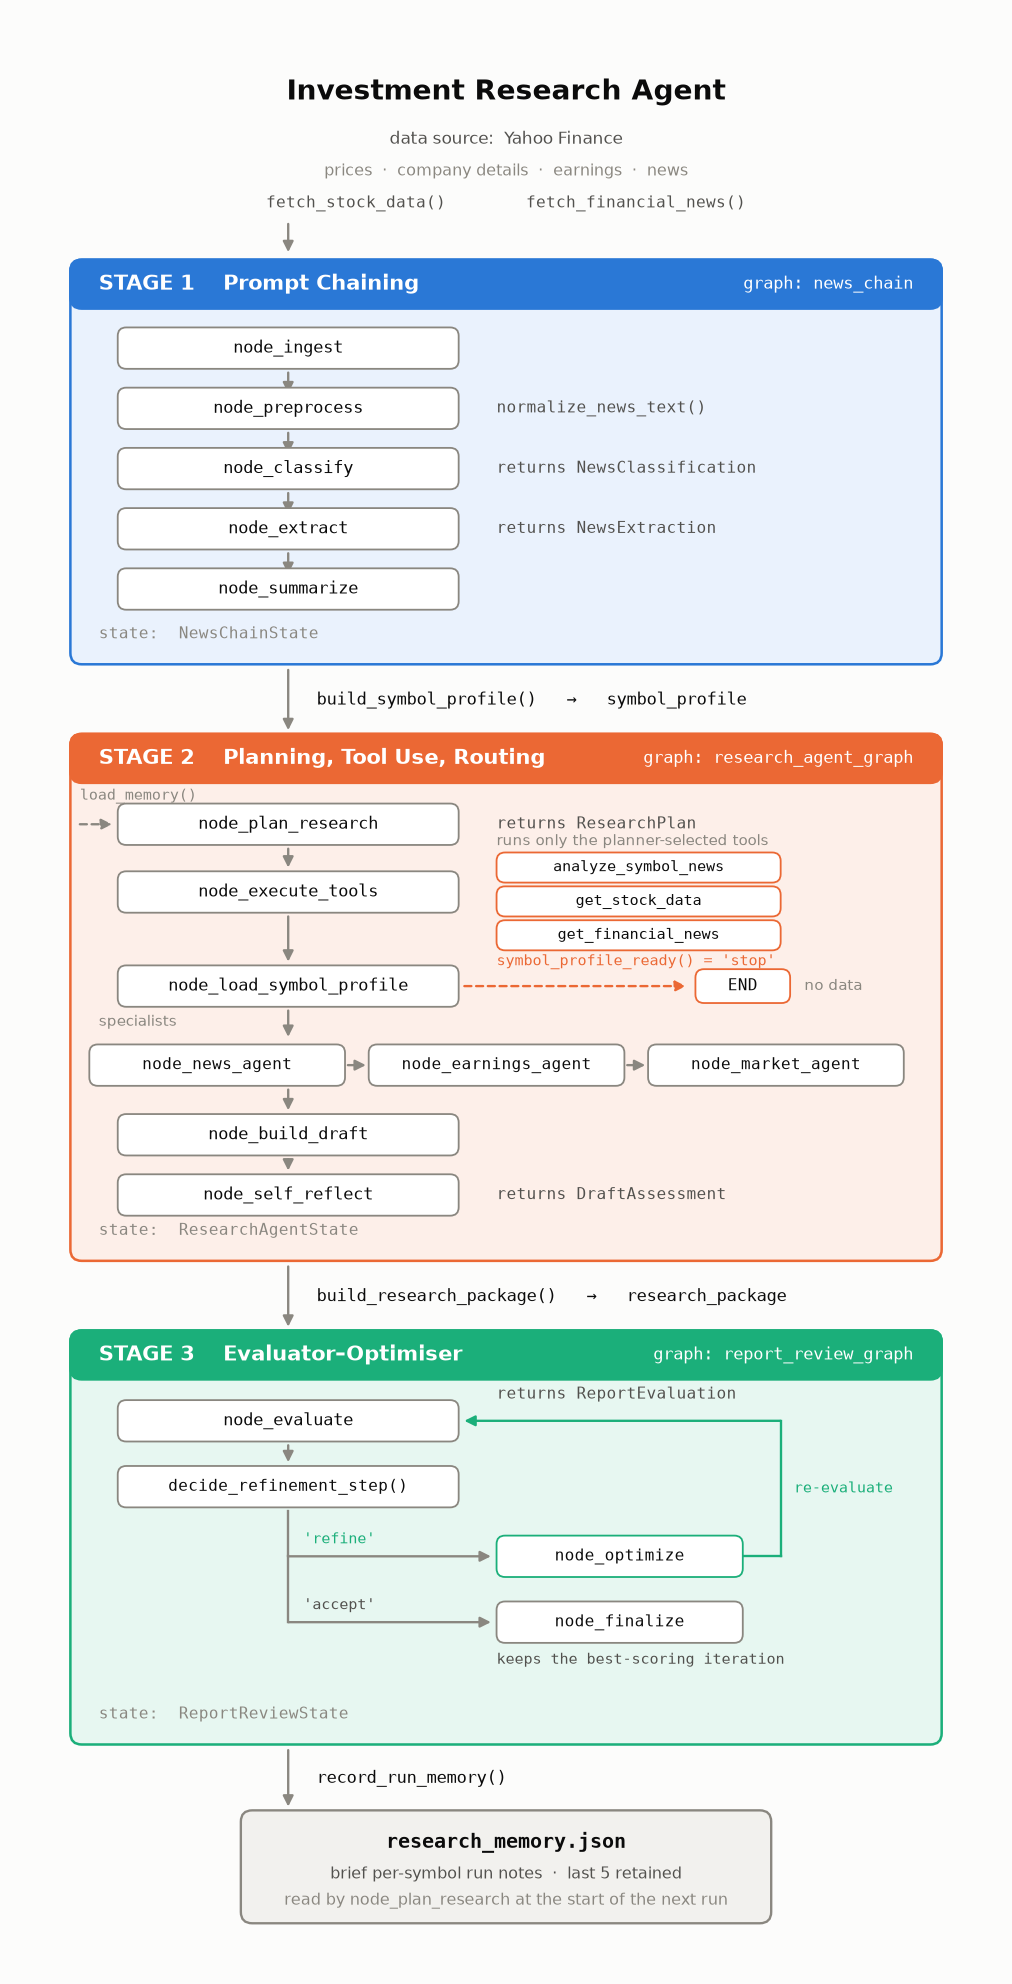">
</div>

Routing is additionally exercised on its own in `routing_graph`, which sends a
single task through `route_research_task()` to whichever of the three
specialists the router selects. A complete review run is entered through
`review_and_refine_report()`, which takes the research package produced by
stage two.

| Stage | Responsibility | Notebook parts |
| --- | --- | --- |
| **1. Data retrieval and prompt chaining** | Retrieve prices, company details and news; clean the text; classify and extract key facts | Parts 2 to 5 |
| **2. Planning, tool use, routing and synthesis** | Plan the research, call the required tools, analyse news, earnings and market data separately, then draft a report and review it | Parts 7 to 10 |
| **3. Evaluation and refinement** | Score the draft against the underlying analyses, revise it using the resulting feedback, and retain the strongest version | Part 11 |

Wherever a step requires the language model to make a decision that controls
program flow — a classification, a routing choice, a pass or fail judgement —
the response is validated against a predefined schema, so subsequent steps
receive well-formed values rather than free-form text. The decision to accept
or reject a report is made in ordinary Python code using numeric thresholds
rather than delegated to the model.

## 3. Workflow patterns

| Pattern | Implementation | Demonstrated in |
| --- | --- | --- |
| **Prompt chaining** | Five ordered steps — ingest, preprocess, classify, extract, summarise — in which each consumes the output of the one before it | Parts 4 and 5 |
| **Routing** | A routing component examines a research task expressed in natural language and directs it to the earnings, news or market specialist | Parts 7 and 10 |
| **Evaluator–optimiser** | A reviewer scores each draft; an optimiser rewrites it from that feedback; the cycle repeats until the report passes or a limit is reached | Part 11 |

## 4. Autonomous agent functions

| Function | Implementation | Demonstrated in |
| --- | --- | --- |
| **Plans its research steps** | A planning component produces an ordered research plan before any data is retrieved | Part 7 |
| **Uses tools dynamically** | Retrieval functions are registered as tools; the planner selects which to call, and only the selected tools execute | Parts 5 and 10 |
| **Self-reflects on output quality** | The agent reviews its own draft for completeness and consistency; the evaluation stage then scores it against the underlying analyses | Parts 9 and 11 |
| **Learns across runs** | A brief, bounded record of each completed run is stored per symbol and read by the planner on subsequent runs | Parts 6 and 12 |

## 5. Data sources

All market and news data is obtained from **Yahoo Finance** through the
`yfinance` library, which requires no API credentials:

- **Prices** — daily closing prices over a one-month window, used to derive the
  current price and the 30-day change
- **Company details** — name, sector, industry, market capitalisation,
  reported revenue and price-to-earnings ratio
- **Earnings** — the most recently *reported* quarter, including estimated and
  actual earnings per share and the resulting surprise
- **News** — recent headlines and summaries, retrieved through the quote
  endpoint, the headline feed, or search results, whichever responds

Because Yahoo Finance is a live service with intermittent availability, every
request is retried before an error is reported, and news retrieval falls back
across several endpoints. Language-model calls are made through the OpenAI API
and require an `OPENAI_API_KEY`.

## 6. Reproducibility and limitations

The notebook is intended to be executed in order from top to bottom. Because
it draws on live market data, figures and news items will differ between runs,
and classifications may shift as the underlying coverage changes. An
intentionally invalid symbol is included throughout the tests so that error
handling is visible alongside the successful cases.

The system summarises and organises information that it retrieves; it does not
verify that information against independent sources, and it does not model or
forecast prices. Its conclusions are limited to what the retrieved data
supports, which the generated reports state explicitly.

# Part 1. Environment and Configuration

Installs the required packages, imports the libraries used throughout, defines
the project-wide settings, and loads the OpenAI credential.

The credential is read from Colab's secret store when available and from an
environment variable otherwise. It is loaded here, at the start, so that a
missing key fails immediately rather than part-way through a long run.

In [ ]:
!pip -q install -U yfinance curl_cffi langgraph langchain-openai pydantic


In [2]:
# Core imports. yfinance supplies market data; LangGraph composes each
# stage as a graph of steps; LangChain provides the prompt templates and
# the schema-validated model wrappers used throughout.
import os
import re
import json
import time
import logging
import datetime
import warnings

warnings.filterwarnings("ignore")

# Hide noisy yfinance messages. Our code returns its own clean errors.
logging.getLogger("yfinance").setLevel(logging.CRITICAL)

import pandas as pd
import yfinance as yf

from xml.etree import ElementTree
from curl_cffi import requests as curl_requests

from typing import Literal, Optional, TypedDict
from pydantic import BaseModel, Field

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, StateGraph

print("Setup complete.")


print("pandas version:", pd.__version__)
print("yfinance version:", yf.__version__)

Setup complete.
pandas version: 3.0.6
yfinance version: 1.7.0


In [3]:
# Project settings

MAX_NEWS_ARTICLES = 5
STOCK_HISTORY_PERIOD = "1mo"

MAX_RETRIES = 3
RETRY_WAIT_SECONDS = 2

LLM_MODEL = "gpt-6-luna"

TEST_SYMBOLS = [
    "AAPL",
    "MSFT",
    "NVDA",
    "SPYFAKE"
]

print("Settings loaded.")

Settings loaded.


In [4]:
# OpenAI credential. Read from Colab's secret store when available,
# otherwise from the environment. Loaded here so a missing key fails
# immediately rather than part-way through a run.


def get_colab_secret(name: str) -> str:
    """Read a secret from Colab or the environment."""
    try:
        from google.colab import userdata

        value = userdata.get(name)

        if value:
            return value

    except Exception:
        pass

    return os.environ.get(name, "")


OPENAI_API_KEY = get_colab_secret(
    "OPENAI_API_KEY"
)

if not OPENAI_API_KEY:
    raise RuntimeError(
        "OPENAI_API_KEY was not found. "
        "Add it in Colab Secrets, turn on "
        "Notebook access, restart the session, "
        "and run this cell again."
    )

os.environ["OPENAI_API_KEY"] = (
    OPENAI_API_KEY
)

print("OpenAI key loaded.")

OpenAI key loaded.


# Part 2. Market Data Retrieval

Retrieves price history, company details and recent earnings from Yahoo
Finance.

Yahoo Finance is a live service that intermittently refuses or throttles
requests, so each category of data is requested independently and retried
before an error is returned. Price history is attempted through two different
endpoints. Company details and earnings are requested in separate loops, so a
failure in either does not discard the price data that was already retrieved.

The test at the end of this part covers three valid symbols and one invalid
symbol, confirming both that real data is returned and that an unknown symbol
produces a clean error rather than an exception.

In [5]:
# Price history retrieval.
# Yahoo serves the same data through two endpoints that fail independently,
# so both are attempted before an error is raised.
def _sleep_before_retry(attempt: int) -> None:
    """Wait before another Yahoo request."""
    if attempt < MAX_RETRIES:
        time.sleep(RETRY_WAIT_SECONDS)


def _download_price_history(symbol: str) -> pd.DataFrame:
    """Download recent price history with retry and fallback."""
    last_error = None

    # First try yf.download.
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            history = yf.download(
                symbol,
                period=STOCK_HISTORY_PERIOD,
                interval="1d",
                progress=False,
                auto_adjust=False,
                threads=False
            )

            if history is not None and not history.empty:
                if isinstance(history.columns, pd.MultiIndex):
                    history.columns = history.columns.get_level_values(0)

                return history

        except Exception as exc:
            last_error = exc

        _sleep_before_retry(attempt)

    # Fallback to Ticker.history.
    for attempt in range(1, MAX_RETRIES + 1):
        try:
            ticker = yf.Ticker(symbol)

            history = ticker.history(
                period=STOCK_HISTORY_PERIOD,
                interval="1d",
                auto_adjust=False
            )

            if history is not None and not history.empty:
                return history

        except Exception as exc:
            last_error = exc

        _sleep_before_retry(attempt)

    if last_error:
        raise RuntimeError(
            f"Yahoo price request failed after retries: {last_error}"
        )

    return pd.DataFrame()

In [6]:
# Assembles the full market-data record for one symbol.
# Price, company details and earnings are requested separately so that a
# failure in one does not discard data already retrieved from another.
def fetch_stock_data(symbol: str) -> dict:
    """Get stock and company data from Yahoo Finance."""
    symbol = symbol.strip().upper()

    if not symbol:
        return {
            "symbol": "",
            "error": "Ticker is empty."
        }

    # Price data
    try:
        history = _download_price_history(symbol)
    except Exception as exc:
        return {
            "symbol": symbol,
            "error": str(exc)
        }

    if history.empty or "Close" not in history.columns:
        return {
            "symbol": symbol,
            "error": (
                f"No price data found for {symbol} "
                f"after {MAX_RETRIES} retries."
            )
        }

    close_series = history["Close"].dropna()

    if close_series.empty:
        return {
            "symbol": symbol,
            "error": f"No closing prices found for {symbol}."
        }

    current_price = round(
        float(close_series.iloc[-1]),
        2
    )

    first_price = float(close_series.iloc[0])

    price_change = None

    if first_price:
        price_change = round(
            (
                (current_price - first_price)
                / first_price
            ) * 100,
            2
        )

    # Company information is separate from price data.
    info = {}

    for attempt in range(1, MAX_RETRIES + 1):
        try:
            ticker = yf.Ticker(symbol)
            candidate = ticker.info

            if isinstance(candidate, dict):
                info = candidate
                break

        except Exception:
            pass

        _sleep_before_retry(attempt)

    # Recent earnings are optional.
    recent_earnings = {}

    for attempt in range(1, MAX_RETRIES + 1):
        try:
            ticker = yf.Ticker(symbol)
            earnings = ticker.earnings_dates

            if earnings is not None and not earnings.empty:
                # earnings_dates is sorted newest first and includes
                # quarters that have not happened yet. Those rows carry
                # an estimate but no reported EPS, so take the most
                # recent row whose date has already passed.
                today = datetime.date.today()

                reported = earnings[
                    earnings.index.date < today
                ]

                frame = (
                    reported
                    if not reported.empty
                    else earnings
                )

                row = frame.iloc[0]

                recent_earnings = {
                    "is_reported": bool(
                        not reported.empty
                    ),
                    "date": str(
                        frame.index[0].date()
                    ),
                    "eps_estimate": row.get(
                        "EPS Estimate"
                    ),
                    "reported_eps": row.get(
                        "Reported EPS"
                    ),
                    "surprise_pct": row.get(
                        "Surprise(%)"
                    ),
                }

                break

        except Exception:
            pass

        _sleep_before_retry(attempt)

    return {
        "symbol": symbol,
        "company_name": (
            info.get("longName")
            or info.get("shortName")
            or symbol
        ),
        "sector": info.get("sector", "N/A"),
        "industry": info.get("industry", "N/A"),
        "current_price": current_price,
        "price_change_30d_pct": price_change,
        "market_cap": info.get("marketCap"),
        "pe_ratio": info.get("trailingPE"),
        "revenue": info.get("totalRevenue"),
        "recent_earnings": recent_earnings,
        "error": None,
    }

In [7]:
# Test Yahoo Finance

for symbol in TEST_SYMBOLS:
    print("\n" + "=" * 50)
    print("Symbol:", symbol)

    result = fetch_stock_data(symbol)

    print(
        json.dumps(
            result,
            indent=2,
            default=str
        )
    )


Symbol: AAPL


{
  "symbol": "AAPL",
  "company_name": "Apple Inc.",
  "sector": "Technology",
  "industry": "Consumer Electronics",
  "current_price": 336.64,
  "price_change_30d_pct": 3.08,
  "market_cap": 4912984883200,
  "pe_ratio": 38.605507,
  "revenue": 466822987776,
  "recent_earnings": {
    "is_reported": true,
    "date": "2026-07-30",
    "eps_estimate": 1.89,
    "reported_eps": 2.02,
    "surprise_pct": 6.74
  },
  "error": null
}

Symbol: MSFT


{
  "symbol": "MSFT",
  "company_name": "Microsoft Corporation",
  "sector": "Technology",
  "industry": "Software - Infrastructure",
  "current_price": 535.07,
  "price_change_30d_pct": 8.66,
  "market_cap": 3973186846720,
  "pe_ratio": 29.111536,
  "revenue": 331839012864,
  "recent_earnings": {
    "is_reported": true,
    "date": "2026-07-29",
    "eps_estimate": 4.24,
    "reported_eps": 4.74,
    "surprise_pct": 11.81
  },
  "error": null
}

Symbol: NVDA


{
  "symbol": "NVDA",
  "company_name": "NVIDIA Corporation",
  "sector": "Technology",
  "industry": "Semiconductors",
  "current_price": 229.28,
  "price_change_30d_pct": 5.0,
  "market_cap": 5536424132608,
  "pe_ratio": 28.986094,
  "revenue": 302970011648,
  "recent_earnings": {
    "is_reported": true,
    "date": "2026-08-26",
    "eps_estimate": 2.09,
    "reported_eps": 2.22,
    "surprise_pct": 6.16
  },
  "error": null
}

Symbol: SPYFAKE


{
  "symbol": "SPYFAKE",
  "error": "No price data found for SPYFAKE after 3 retries."
}


# Part 3. News Retrieval

Retrieves recent news articles for a symbol.

Three Yahoo Finance endpoints are tried in order, and the first that returns
articles is used. This fallback exists because the quote news endpoint has been
observed to return an empty list while the other two continue to serve data;
without it, the news stage of the pipeline silently receives nothing.

The headline feed is preferred over search results because it supplies article
descriptions as well as titles, and the analysis steps that follow depend on
that additional text.

In [8]:
# News retrieval across three Yahoo endpoints.
# Each loader normalises its response into one shape so the parsing below
# is shared, and the first endpoint returning articles wins.
def _news_from_ticker(symbol: str) -> list:
    """Yahoo quote news endpoint. Preferred when it returns data."""
    return yf.Ticker(symbol).news or []


def _news_from_rss(symbol: str) -> list:
    """Yahoo headline RSS feed. Carries titles and descriptions."""
    url = (
        "https://feeds.finance.yahoo.com/rss/2.0/headline"
        f"?s={symbol}&region=US&lang=en-US"
    )

    response = curl_requests.get(
        url,
        impersonate="chrome",
        timeout=20
    )

    if response.status_code != 200:
        return []

    root = ElementTree.fromstring(
        response.content
    )

    items = []

    for entry in root.findall(".//item"):

        items.append({
            "title": (
                entry.findtext("title") or ""
            ).strip(),
            "summary": (
                entry.findtext("description")
                or ""
            ).strip(),
            "pubDate": (
                entry.findtext("pubDate") or ""
            ).strip(),
            "canonicalUrl": {
                "url": (
                    entry.findtext("link") or ""
                ).strip()
            },
            "provider": {
                "displayName": "Yahoo Finance RSS"
            },
        })

    return items


def _news_from_search(symbol: str) -> list:
    """Yahoo search results. Titles only, so this is the last resort."""
    results = yf.Search(
        symbol,
        news_count=MAX_NEWS_ARTICLES
    ).news or []

    return [
        {
            "title": item.get("title", ""),
            "summary": "",
            "pubDate": item.get(
                "providerPublishTime",
                ""
            ),
            "canonicalUrl": {
                "url": item.get("link", "")
            },
            "provider": {
                "displayName": item.get(
                    "publisher",
                    ""
                )
            },
        }
        for item in results
    ]


# Tried in order. Ticker.news stays first so behaviour is unchanged
# whenever Yahoo serves it. The other two cover the case where it
# returns nothing, which is what happens at the moment.
NEWS_SOURCES = (
    ("ticker", _news_from_ticker),
    ("rss", _news_from_rss),
    ("search", _news_from_search),
)


def fetch_financial_news(
    symbol: str,
    limit: int = MAX_NEWS_ARTICLES
) -> list:
    """Get recent financial news from Yahoo Finance."""
    symbol = symbol.strip().upper()

    if not symbol:
        return []

    last_error = None

    for attempt in range(1, MAX_RETRIES + 1):

        for source_name, load_news in NEWS_SOURCES:

            try:
                raw_news = load_news(symbol)

            except Exception as exc:
                last_error = exc
                continue

            if not raw_news:
                continue

            articles = []

            for item in raw_news[:limit]:
                content = item.get(
                    "content",
                    item
                )

                provider = content.get(
                    "provider",
                    {}
                )

                if isinstance(provider, dict):
                    publisher = provider.get(
                        "displayName",
                        ""
                    )
                else:
                    publisher = str(provider)

                url_info = content.get(
                    "canonicalUrl",
                    {}
                )

                if isinstance(url_info, dict):
                    url = url_info.get(
                        "url",
                        ""
                    )
                else:
                    url = (
                        content.get("link", "")
                        or str(url_info)
                    )

                title = (
                    content.get("title", "")
                    or item.get("title", "")
                )

                description = (
                    content.get("summary", "")
                    or content.get(
                        "description",
                        ""
                    )
                    or item.get("summary", "")
                )

                if not title and not description:
                    continue

                articles.append({
                    "symbol": symbol,
                    "title": title,
                    "description": description,
                    "published_at": (
                        content.get("pubDate", "")
                        or item.get(
                            "providerPublishTime",
                            ""
                        )
                    ),
                    "publisher": (
                        publisher
                        or item.get(
                            "publisher",
                            ""
                        )
                    ),
                    "url": (
                        url
                        or item.get("link", "")
                    ),
                    "source": "Yahoo Finance",
                    "feed": source_name,
                })

            if articles:
                return articles[:limit]

        _sleep_before_retry(attempt)

    if last_error:
        print(
            f"News request failed for {symbol}: "
            f"{last_error}"
        )

    return []

In [9]:
# Quick news check for all real test stocks

for symbol in ["AAPL", "MSFT", "NVDA"]:
    articles = fetch_financial_news(symbol)

    print(
        symbol,
        "- articles:",
        len(articles)
    )

    for article in articles[:2]:
        print("  -", article["title"])

AAPL - articles: 5
  - Apple discloses deal to hire team and license tech from personalized podcast startup Huxe
  - Apple’s App Store Growth Improved in September. What UBS Sees Coming in October Is Harder


MSFT - articles: 5
  - Trump awards science medals to Musk, Nadella and 4 other tech titans — 5 immigrants — hours after Vance targets them
  - Microsoft (MSFT) Posted 43% Azure Growth, Yet Trades Below Its Own Five-Year P/E. A Real Discount?


NVDA - articles: 5
  - Amazon (AMZN) Wants Investors to Finance $8 Billion of Nvidia Chips. Is AI Spending Getting Too Heavy?
  - ‘Big Short’ investors split over the AI risk that matters most


# Part 4. Stage 1 — Prompt Chaining

Implements the first workflow pattern as a five-step chain:

**Ingest → Preprocess → Classify → Extract → Summarise**

Each step consumes the output of the step before it. The classification
produced in step three is supplied to the extraction step, and both the
classification and the extracted facts are supplied to the summarisation step.

Two of the steps return structured objects validated against a schema, so the
category, sentiment and extracted lists arrive as well-formed Python values.
Every step after the first begins by checking whether an error has already been
recorded, and returns immediately if so, which allows a failure during
retrieval to propagate without raising an exception.

In [10]:
# Schemas for the two chain steps whose results drive later steps.
# Constraining category and sentiment to fixed sets means downstream code
# can branch on them without parsing free text.
class NewsClassification(BaseModel):
    category: Literal[
        "earnings",
        "analyst_opinion",
        "market_news"
    ]

    confidence: Literal[
        "low",
        "medium",
        "high"
    ]


class NewsExtraction(BaseModel):
    sentiment: Literal[
        "positive",
        "neutral",
        "negative"
    ]

    key_events: list[str] = Field(
        default_factory=list
    )

    entities: list[str] = Field(
        default_factory=list
    )

    key_figures: list[str] = Field(
        default_factory=list
    )

In [11]:
# Shared state for the prompt chain. total=False allows each step to return
# only the keys it sets, which LangGraph merges into the running state.
class NewsChainState(
    TypedDict,
    total=False
):
    symbol: str

    stock_data: dict
    articles: list

    cleaned_articles: list
    cleaned_text: str

    category: str
    category_confidence: str

    sentiment: str
    key_events: list
    entities: list
    key_figures: list

    summary: str

    error: Optional[str]

In [12]:
llm = ChatOpenAI(
    model=LLM_MODEL
)

classification_llm = (
    llm.with_structured_output(
        NewsClassification
    )
)

extraction_llm = (
    llm.with_structured_output(
        NewsExtraction
    )
)

print("LLM ready.")

LLM ready.


In [13]:
# Light text normalisation applied before the news reaches the model.
def normalize_news_text(text: str) -> str:
    """Remove simple text noise."""
    if not text:
        return ""

    text = re.sub(
        r"https?://\S+",
        "",
        text
    )

    # Apostrophes are kept so possessives and contractions survive.
    text = re.sub(
        r"[^\w\s\.,!?%$\-']",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    )

    return text.strip()

In [14]:
# Chain step 1 of 5. Retrieves the raw material and records an error that
# every later step checks, so a failure short-circuits without raising.
def node_ingest(
    state: NewsChainState
) -> dict:
    """Stage 1: get stock data and news."""
    symbol = state["symbol"]

    stock_data = fetch_stock_data(
        symbol
    )

    if stock_data.get("error"):
        return {
            "stock_data": stock_data,
            "articles": [],
            "error": stock_data["error"],
        }

    articles = fetch_financial_news(
        symbol
    )

    if not articles:
        return {
            "stock_data": stock_data,
            "articles": [],
            "error": (
                f"No news found for {symbol}."
            ),
        }

    return {
        "stock_data": stock_data,
        "articles": articles,
        "error": None,
    }

In [15]:
# Chain step 2 of 5. Produces one combined text block for the model from
# the cleaned titles and descriptions.
def node_preprocess(
    state: NewsChainState
) -> dict:
    """Stage 2: clean the news text."""
    if state.get("error"):
        return {}

    cleaned_articles = []

    for article in state.get(
        "articles",
        []
    ):
        cleaned_articles.append({
            **article,
            "clean_title": normalize_news_text(
                article.get(
                    "title",
                    ""
                )
            ),
            "clean_description": normalize_news_text(
                article.get(
                    "description",
                    ""
                )
            ),
        })

    cleaned_text = " ".join(
        (
            f"{article['clean_title']}. "
            f"{article['clean_description']}"
        )
        for article in cleaned_articles
    ).strip()

    if not cleaned_text:
        return {
            "cleaned_articles": (
                cleaned_articles
            ),
            "cleaned_text": "",
            "error": (
                "News text is empty "
                "after cleaning."
            ),
        }

    return {
        "cleaned_articles": (
            cleaned_articles
        ),
        "cleaned_text": cleaned_text,
    }

In [16]:
# Chain steps 3 to 5. Each prompt is paired with the node that uses it.
# The category from step 3 feeds step 4, and both feed step 5.


CLASSIFY_PROMPT = (
    ChatPromptTemplate.from_template(
        """
Classify the main topic of this financial news for {symbol}.

Choose one category:
- earnings
- analyst_opinion
- market_news

News:
{cleaned_text}

Use only the news provided.
"""
    )
)


def node_classify(
    state: NewsChainState
) -> dict:
    """Stage 3: classify the news."""
    if state.get("error"):
        return {}

    prompt = CLASSIFY_PROMPT.invoke({
        "symbol": state["symbol"],
        "cleaned_text": (
            state["cleaned_text"]
        ),
    })

    result = (
        classification_llm.invoke(
            prompt
        )
    )

    return {
        "category": result.category,
        "category_confidence": (
            result.confidence
        ),
    }


EXTRACT_PROMPT = (
    ChatPromptTemplate.from_template(
        """
The news for {symbol} was classified as {category}.

Use only the text below.

News:
{cleaned_text}

Extract:
1. sentiment
2. up to 5 key events
3. named entities
4. important financial figures

Do not add facts that are not in the news.
"""
    )
)


def node_extract(
    state: NewsChainState
) -> dict:
    """Stage 4: extract the main facts."""
    if state.get("error"):
        return {}

    prompt = EXTRACT_PROMPT.invoke({
        "symbol": state["symbol"],
        "category": state["category"],
        "cleaned_text": (
            state["cleaned_text"]
        ),
    })

    result = (
        extraction_llm.invoke(
            prompt
        )
    )

    return {
        "sentiment": result.sentiment,
        "key_events": result.key_events,
        "entities": result.entities,
        "key_figures": (
            result.key_figures
        ),
    }


SUMMARIZE_PROMPT = (
    ChatPromptTemplate.from_template(
        """
Write a short 2-sentence financial research summary for {symbol}.

Category: {category}
Sentiment: {sentiment}
Key events: {key_events}
Key figures: {key_figures}
Current price: {current_price}
30-day price change: {price_change}%

Use only the information provided.
"""
    )
)


def node_summarize(
    state: NewsChainState
) -> dict:
    """Stage 5: write the summary."""
    if state.get("error"):
        return {
            "summary": ""
        }

    stock_data = state.get(
        "stock_data",
        {}
    )

    chain = (
        SUMMARIZE_PROMPT
        | llm
        | StrOutputParser()
    )

    summary = chain.invoke({
        "symbol": state["symbol"],
        "category": state["category"],
        "sentiment": state["sentiment"],
        "key_events": (
            state["key_events"]
        ),
        "key_figures": (
            state["key_figures"]
        ),
        "current_price": stock_data.get(
            "current_price"
        ),
        "price_change": stock_data.get(
            "price_change_30d_pct"
        ),
    })

    return {
        "summary": summary.strip()
    }

In [17]:
# Composes the five steps into a linear graph and compiles it.
# Build the LangGraph workflow

builder = StateGraph(
    NewsChainState
)

builder.add_node(
    "ingest",
    node_ingest
)

builder.add_node(
    "preprocess",
    node_preprocess
)

builder.add_node(
    "classify",
    node_classify
)

builder.add_node(
    "extract",
    node_extract
)

builder.add_node(
    "summarize",
    node_summarize
)

builder.set_entry_point(
    "ingest"
)

builder.add_edge(
    "ingest",
    "preprocess"
)

builder.add_edge(
    "preprocess",
    "classify"
)

builder.add_edge(
    "classify",
    "extract"
)

builder.add_edge(
    "extract",
    "summarize"
)

builder.add_edge(
    "summarize",
    END
)

news_chain = builder.compile()

print(
    "Prompt Chaining ready: "
    "Ingest -> Preprocess -> "
    "Classify -> Extract -> Summarize"
)

Prompt Chaining ready: Ingest -> Preprocess -> Classify -> Extract -> Summarize


# Part 5. Stage 1 — Output Contract, Tools and Verification

Converts the final chain state into a flat record for the next stage, exposes
the retrieval functions and the whole chain as callable tools, and verifies the
result.

Registering the chain as a tool is what allows the planning component in Part 7
to invoke it dynamically rather than having it hard-wired into the pipeline.

The verification step requires each valid symbol to produce a complete record
with a recognised category, a recognised sentiment, at least one article and a
non-empty summary. The invalid symbol passes the same check by producing an
error, which confirms that failures are reported rather than hidden. Because
the data is live, the categories and figures shown will differ between runs.

In [18]:
# Flattens the final chain state into the record passed to stage two.
# This is the contract between the two stages: fields added here become
# available to the planner and the specialists.
def build_symbol_profile(
    state: dict
) -> dict:
    """Flatten the chain state into the symbol profile used downstream."""
    stock_data = state.get(
        "stock_data",
        {}
    )

    return {
        "symbol": state.get("symbol"),

        "company_name": stock_data.get(
            "company_name",
            state.get("symbol")
        ),

        "sector": stock_data.get(
            "sector"
        ),

        "industry": stock_data.get(
            "industry"
        ),

        "market_cap": stock_data.get(
            "market_cap"
        ),

        "revenue": stock_data.get(
            "revenue"
        ),

        "category": state.get(
            "category"
        ),

        "category_confidence": state.get(
            "category_confidence"
        ),

        "sentiment": state.get(
            "sentiment"
        ),

        "current_price": stock_data.get(
            "current_price"
        ),

        "price_change_30d_pct": (
            stock_data.get(
                "price_change_30d_pct"
            )
        ),

        "pe_ratio": stock_data.get(
            "pe_ratio"
        ),

        "recent_earnings": stock_data.get(
            "recent_earnings",
            {}
        ),

        "entities": state.get(
            "entities",
            []
        ),

        "key_events": state.get(
            "key_events",
            []
        ),

        "key_figures": state.get(
            "key_figures",
            []
        ),

        "article_count": len(
            state.get(
                "cleaned_articles",
                []
            )
        ),

        "summary": state.get(
            "summary",
            ""
        ),

        "error": state.get(
            "error"
        ),

        "source": "Yahoo Finance",

        "date": str(
            datetime.date.today()
        ),
    }

In [19]:
# Registers the retrieval functions and the whole chain as tools, so the
# planner in Part 7 can select them at run time.
@tool
def get_stock_data(
    symbol: str
) -> dict:
    """Get stock and company data."""
    return fetch_stock_data(symbol)


@tool
def get_financial_news(
    symbol: str
) -> list:
    """Get recent financial news."""
    return fetch_financial_news(
        symbol
    )


@tool
def analyze_symbol_news(
    symbol: str
) -> dict:
    """Run the news analysis chain for one symbol."""
    final_state = (
        news_chain.invoke({
            "symbol": (
                symbol.strip().upper()
            )
        })
    )

    return build_symbol_profile(
        final_state
    )


RESEARCH_TOOLS = [
    get_stock_data,
    get_financial_news,
    analyze_symbol_news,
]

print("Research tools ready.")

for item in RESEARCH_TOOLS:
    print("-", item.name)

Research tools ready.
- get_stock_data
- get_financial_news
- analyze_symbol_news


In [20]:
# Runs the complete stage-one pipeline over the test symbols.
results = {}

for symbol in TEST_SYMBOLS:
    print("\n" + "=" * 60)
    print("Symbol:", symbol)

    try:
        result = (
            analyze_symbol_news.invoke({
                "symbol": symbol
            })
        )

        results[symbol] = result

        if result.get("error"):
            print("Status: error")
            print(
                "Message:",
                result["error"]
            )

        else:
            print("Status: ok")
            print(
                "Category:",
                result["category"]
            )
            print(
                "Sentiment:",
                result["sentiment"]
            )
            print(
                "Price:",
                result["current_price"]
            )
            print(
                "Articles:",
                result["article_count"]
            )
            print(
                "Entities:",
                result["entities"]
            )
            print(
                "Key events:",
                result["key_events"]
            )
            print(
                "Key figures:",
                result["key_figures"]
            )
            print(
                "Summary:",
                result["summary"]
            )

    except Exception as exc:
        results[symbol] = {
            "symbol": symbol,
            "error": str(exc)
        }

        print("Status: error")
        print("Message:", exc)


Symbol: AAPL


Status: ok
Category: analyst_opinion
Sentiment: neutral
Price: 336.64
Articles: 5
Entities: ['Apple', 'AAPL', 'Huxe', 'UBS', 'David Vogt', 'Tim Cook', 'John Ternus', 'Gene Munster', 'App Store', 'iPhone 18 Pro', 'iPhone 18 Pro Max', 'iPhone Duo']
Key events: ['Apple disclosed a deal to hire a team and license technology from personalized podcast startup Huxe.', 'UBS reported that App Store revenue grew 5% year over year in September, after no growth in August; analyst David Vogt said it was too early to draw broader conclusions.', 'Reports said Apple asked suppliers to cut October orders for iPhone 18 Pro and Pro Max components amid softer demand and higher memory chip costs.', "Gene Munster said the distinction between iPhone 18 Pro and Pro Max demand could indicate how consumers are responding to Apple's split product cycle.", "Tim Cook's final earnings call showed Apple generated more quarterly revenue than it recorded in all of fiscal 2011, as John Ternus inherits the company."]
Ke

Status: ok
Category: analyst_opinion
Sentiment: neutral
Price: 535.07
Articles: 5
Entities: ['Donald Trump', 'Elon Musk', 'Satya Nadella', 'Vance', 'Microsoft', 'MSFT', 'Azure', 'Alphabet', 'GOOGL', 'Big Tech', 'Healthcare']
Key events: ['Trump awarded science medals to Elon Musk, Satya Nadella, and four other technology leaders.', 'Vance criticized foreign technology workers and Microsoft suspended its PERM program.', 'Azure surpassed $100 billion in annual revenue for fiscal 2026; Azure and other cloud services grew 43% in the fiscal fourth quarter.', 'Microsoft traded at about 59 times trailing free cash flow, compared with Alphabet at 80 times.', 'The article discussed whether healthcare can realize productivity gains from the $700 billion Big Tech is betting on AI.']
Key figures: ['Azure annual revenue exceeded $100 billion for fiscal 2026.', 'Azure and other cloud services grew 43% in the fiscal fourth quarter, unchanged in constant currency.', 'Microsoft traded at about 59 times

Status: ok
Category: analyst_opinion
Sentiment: neutral
Price: 229.28
Articles: 5
Entities: ['Amazon.com, Inc. (Amazon, AMZN)', 'Nvidia (NVDA)', 'Steve Eisman', 'Michael Burry', 'Meta', 'FormFactor (FORM)']
Key events: ['Amazon is reportedly considering moving about $8 billion of Nvidia Grace Blackwell chips into a special-purpose vehicle funded by outside investors, then leasing the hardware back.', "Amazon's capital spending is expected to reach $220 billion this year.", 'Steve Eisman said Michael Burry may be focused on the wrong risk in the AI boom.', 'Nvidia reported a quarter in which revenue more than doubled, while its valuation was described as below its level over the past five years.', 'FormFactor was described as potentially 33% undervalued after AI testing news; its shares have returned 312.4% over three years.']
Key figures: ['$8 billion in Nvidia Grace Blackwell chips', '$220 billion in expected Amazon capital spending this year', 'Nvidia revenue more than doubled in a r

Status: error
Message: No price data found for SPYFAKE after 3 retries.


In [21]:
# Verifies each result. Valid symbols must produce a complete record with
# recognised values; the invalid symbol passes by producing an error.
# Check the final output

required_fields = [
    "symbol",
    "company_name",
    "category",
    "sentiment",
    "current_price",
    "entities",
    "key_events",
    "key_figures",
    "article_count",
    "summary",
    "error",
    "source",
    "date",
]

check_rows = []

for symbol, result in results.items():

    if symbol == "SPYFAKE":
        passed = bool(
            result.get("error")
        )

    else:
        has_fields = all(
            field in result
            for field in required_fields
        )

        has_output = (
            result.get("category")
            in {
                "earnings",
                "analyst_opinion",
                "market_news"
            }
            and result.get("sentiment")
            in {
                "positive",
                "neutral",
                "negative"
            }
            and result.get(
                "article_count",
                0
            ) > 0
            and bool(
                result.get("summary")
            )
            and not result.get("error")
        )

        passed = (
            has_fields
            and has_output
        )

    check_rows.append({
        "Symbol": symbol,
        "Result": (
            "PASS"
            if passed
            else "CHECK"
        ),
        "Category": result.get(
            "category",
            "-"
        ),
        "Sentiment": result.get(
            "sentiment",
            "-"
        ),
        "Articles": result.get(
            "article_count",
            0
        ),
        "Error": result.get(
            "error",
            ""
        ),
    })

validation_table = pd.DataFrame(
    check_rows
)

validation_table

,Symbol,Result,Category,Sentiment,Articles,Error
0,AAPL,PASS,analyst_opinion,neutral,5,NaN
1,MSFT,PASS,analyst_opinion,neutral,5,NaN
2,NVDA,PASS,analyst_opinion,neutral,5,NaN
3,SPYFAKE,PASS,NaN,NaN,0,No price data found for SPYFAKE after 3 retries.


In [22]:
os.makedirs(
    "data",
    exist_ok=True
)

output_file = (
    "data/symbol_profiles.json"
)

_INFINITY = float("inf")


def json_safe(value):
    """Replace NaN and Infinity with None so the file is valid JSON.

    Yahoo returns NaN for an unreported EPS or surprise. json.dump emits
    those as bare NaN, which the JSON spec does not allow and strict
    parsers reject.
    """
    if isinstance(value, float):
        is_nan = value != value

        if is_nan or value in (
            _INFINITY,
            -_INFINITY
        ):
            return None

        return value

    if isinstance(value, dict):
        return {
            key: json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_safe(item)
            for item in value
        ]

    return value


with open(
    output_file,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        json_safe(results),
        file,
        indent=2,
        default=str,
        allow_nan=False
    )

print("Saved:", output_file)

Saved: data/symbol_profiles.json


# Part 6. Agent Memory — Learning Across Runs

Implements the fourth agent function. A short record of each completed run is
stored as JSON keyed by stock symbol, and the planning step reads those records
before deciding what the next run should prioritise.

Two properties are enforced in code rather than merely requested of the model:

- **The notes stay brief.** Each record carries one lesson capped at 200
  characters by its schema, and only the five most recent records per symbol
  are retained.
- **Only genuine runs are recorded.** The deliberately flawed draft used in
  Part 11 to test the refinement loop is excluded, so a sabotaged run cannot
  contaminate what the agent carries forward.

Prior notes are supplied to the planning step only. They are deliberately kept
out of the report-writing and evaluation steps, so that figures recorded
earlier can never be mistaken for current facts about the company.

Part 12 demonstrates the complete cycle.

In [23]:
# Agent memory: brief, per-symbol notes carried between runs.

MEMORY_PATH = "research_memory.json"

# Keep the store short. Both limits are enforced here, not left to the model.
MEMORY_KEEP = 5
MAX_LESSON_CHARS = 200


class RunLesson(BaseModel):
    """One bounded lesson carried forward to the next run."""

    lesson: str = Field(
        max_length=MAX_LESSON_CHARS,
        description=(
            "One sentence on what the next research run for this "
            "symbol should do differently or pay attention to."
        )
    )


lesson_llm = llm.with_structured_output(RunLesson)


def _read_store() -> dict:
    """Load the memory file. A missing or damaged file is not fatal."""
    if not os.path.exists(MEMORY_PATH):
        return {}

    try:
        with open(
            MEMORY_PATH,
            encoding="utf-8"
        ) as file:
            store = json.load(file)

    except (OSError, ValueError):
        # A research run must not fail because of a bad memory file.
        return {}

    return store if isinstance(store, dict) else {}


def _write_store(store: dict) -> None:
    with open(
        MEMORY_PATH,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            store,
            file,
            indent=2,
            default=str,
            allow_nan=False
        )


def load_memory(symbol: str) -> str:
    """Return prior notes for a symbol as text the planner can read."""
    notes = _read_store().get(
        symbol.strip().upper(),
        []
    )

    if not notes:
        return (
            "No prior research notes for this symbol."
        )

    lines = []

    for note in notes[-MEMORY_KEEP:]:
        lines.append(
            "- [{stamp}] price {price}, 30-day change {change}%, "
            "category {category}, sentiment {sentiment}, "
            "{articles} articles, evaluator score {score}. "
            "Lesson: {lesson}".format(
                stamp=note.get("timestamp", "unknown"),
                price=note.get("price"),
                change=note.get("price_change_30d_pct"),
                category=note.get("category"),
                sentiment=note.get("sentiment"),
                articles=note.get("article_count"),
                score=note.get("evaluator_score"),
                lesson=note.get("lesson", ""),
            )
        )

    return "\n".join(lines)


def append_memory(
    symbol: str,
    record: dict
) -> dict:
    """Store one record, keeping only the most recent MEMORY_KEEP entries."""
    store = _read_store()

    key = symbol.strip().upper()

    notes = store.get(key, [])
    notes.append(record)

    store[key] = notes[-MEMORY_KEEP:]

    _write_store(store)

    return record


LESSON_PROMPT = ChatPromptTemplate.from_template(
    """
A research run for {symbol} has finished.

Evaluator score: {score}
Accepted: {accepted}
News articles available: {articles}

Issues the reviewer raised:
{issues}

Write one sentence, at most {limit} characters, stating what the next
research run for {symbol} should do differently or pay closer attention to.

Write about the research process and the data it relies on.
Do not give buy, sell, or hold advice.
Do not predict the share price.
"""
)


def record_run_memory(
    research_package: dict,
    review_result: dict
) -> dict:
    """Derive one brief record from a finished run and store it."""
    symbol = research_package.get("symbol")

    history = review_result.get(
        "history",
        []
    )

    first = history[0] if history else {}

    issues = first.get("issues", [])

    issue_text = "\n".join(
        f"- {item}"
        for item in issues
    ) or "- none"

    try:
        prompt = LESSON_PROMPT.invoke({
            "symbol": symbol,
            "score": review_result.get(
                "final_score"
            ),
            "accepted": review_result.get(
                "final_passed"
            ),
            "articles": research_package.get(
                "article_count"
            ),
            "issues": issue_text,
            "limit": MAX_LESSON_CHARS,
        })

        lesson = lesson_llm.invoke(
            prompt
        ).lesson

    except Exception as exc:
        # Fall back to the reviewer's own wording rather than losing
        # the record entirely.
        lesson = (
            issues[0]
            if issues
            else f"No lesson generated ({exc})."
        )

    record = {
        "timestamp": (
            datetime.datetime.now(
                datetime.timezone.utc
            ).isoformat(
                timespec="seconds"
            )
        ),
        "price": research_package.get(
            "current_price"
        ),
        "price_change_30d_pct": (
            research_package.get(
                "price_change_30d_pct"
            )
        ),
        "category": research_package.get(
            "category"
        ),
        "sentiment": research_package.get(
            "sentiment"
        ),
        "article_count": research_package.get(
            "article_count"
        ),
        "evaluator_score": review_result.get(
            "final_score"
        ),
        "accepted": review_result.get(
            "final_passed"
        ),
        "lesson": str(lesson)[
            :MAX_LESSON_CHARS
        ],
    }

    return append_memory(symbol, record)


print("Agent memory ready:", MEMORY_PATH)

Agent memory ready: research_memory.json


# Part 7. Stage 2 — Planning, Tool Use and Routing

Begins the second stage. Three agent capabilities appear here.

**Planning.** Before any data is retrieved, a planning component produces an
ordered research plan for the requested symbol, along with the tools and
specialists it considers necessary. The notes stored in Part 6 are supplied to
this step, which is the mechanism by which earlier runs influence later ones.

**Tool use.** The plan names which registered tools to call. Only those tools
are executed, and their results are collected into the shared state.

**Routing.** A routing component examines a research task expressed in natural
language and returns the specialist that should handle it, together with the
reason for that choice. Routing is exercised against labelled test cases in
Part 10.

In [24]:
# Shared state for stage two. Each node returns only the keys it sets.
from typing import TypedDict, Optional


class ResearchAgentState(TypedDict, total=False):
    """Shared state for the Investment Research Agent."""

    symbol: str

    # Symbol profile produced by the news chain
    symbol_profile: dict

    # Prior-run notes read by the planner (learning across runs)
    memory_context: str

    # Planning
    research_plan: list[str]
    required_tools: list[str]
    required_agents: list[str]

    # Dynamic tool execution
    tool_results: dict

    # Fields backfilled from planner-selected supplementary tools
    supplementary_fields: list[str]

    # Routing
    route: str
    current_task: str

    # Specialist results
    news_analysis: str
    earnings_analysis: str
    market_analysis: str

    # Final research outputs
    draft_report: str
    self_reflection: dict

    error: Optional[str]

In [25]:
# Planning Node
class ResearchPlan(BaseModel):
    """Structured plan generated by the Investment Research Agent."""

    research_steps: list[str] = Field(
        description="Ordered research tasks that should be completed."
    )

    required_tools: list[
        Literal[
            "analyze_symbol_news",
            "get_stock_data",
            "get_financial_news"
        ]
    ]

    required_agents: list[
        Literal[
            "news",
            "earnings",
            "market"
        ]
    ]


planner_llm = llm.with_structured_output(
    ResearchPlan
)

PLANNER_PROMPT = ChatPromptTemplate.from_template(
    """
You are an Investment Research Planning Agent.

Your task is to create a research plan for stock symbol {symbol}.

PRIOR RESEARCH NOTES FOR {symbol}:
{memory_context}

These notes come from earlier runs of this agent. Use them to decide what
this run should prioritise or check more carefully. They are past
observations, not current facts about the company, so do not repeat their
figures as if they were current, and do not treat them as findings of
this run.

Available tools:

1. analyze_symbol_news
   Returns processed financial news, sentiment, events,
   entities, key figures, current price, recent earnings,
   and summary.

2. get_stock_data
   Returns stock price, company information,
   valuation information, and recent earnings.

3. get_financial_news
   Returns recent financial news articles.

Available specialist agents:

- news
- earnings
- market

Create an ordered research plan.

Always include analyze_symbol_news because its structured
output is required by the specialist agents.

Choose get_stock_data and get_financial_news only when they
provide additional information required by the research plan.

Select the specialist agents needed for a complete investment
research analysis.

Do not perform the research yet.
Only create the plan.
"""
)

# Add the planning node:

def node_plan_research(
    state: ResearchAgentState
) -> dict:
    """Create the research plan before executing tools."""

    symbol = state["symbol"]

    # Learning across runs: prior notes shape this run's plan.
    memory_context = load_memory(symbol)

    prompt = PLANNER_PROMPT.invoke({
        "symbol": symbol,
        "memory_context": memory_context,
    })

    plan = planner_llm.invoke(prompt)

    return {
        "memory_context": memory_context,
        "research_plan": plan.research_steps,
        "required_tools": plan.required_tools,
        "required_agents": plan.required_agents,
    }

In [26]:
# Bridges the news chain into the research workflow and decides whether
# work can continue.
# Integration Node

# Fields the supplementary stock tool can supply if the pipeline left a gap.
BACKFILL_FIELDS = (
    "company_name",
    "sector",
    "industry",
    "market_cap",
    "revenue",
    "current_price",
    "price_change_30d_pct",
    "pe_ratio",
    "recent_earnings",
)


def _is_empty(value) -> bool:
    """True for the placeholder values Yahoo leaves behind."""
    return value in (None, "", {}, [], "N/A")


def node_load_symbol_profile(
    state: ResearchAgentState
) -> dict:
    """Load the prompt-chain output into the research workflow."""

    tool_results = state.get(
        "tool_results",
        {}
    )

    symbol_profile = tool_results.get(
        "analyze_symbol_news",
        {}
    )

    if not symbol_profile:
        return {
            "symbol_profile": {},
            "error": (
                "analyze_symbol_news was not executed "
                "or returned no data."
            )
        }

    if symbol_profile.get("error"):
        return {
            "symbol_profile": symbol_profile,
            "error": symbol_profile["error"]
        }

    # The planner can also select get_stock_data and get_financial_news.
    # Those were previously executed and discarded. Use them to fill gaps
    # the pipeline left, so the planner's tool choice actually matters.
    merged = dict(symbol_profile)
    filled = []

    extra_stock = tool_results.get(
        "get_stock_data"
    )

    if (
        isinstance(extra_stock, dict)
        and not extra_stock.get("error")
    ):
        for field in BACKFILL_FIELDS:
            if (
                _is_empty(merged.get(field))
                and not _is_empty(
                    extra_stock.get(field)
                )
            ):
                merged[field] = extra_stock[field]
                filled.append(field)

    extra_news = tool_results.get(
        "get_financial_news"
    )

    if (
        isinstance(extra_news, list)
        and extra_news
        and not merged.get("article_count")
    ):
        merged["article_count"] = len(
            extra_news
        )
        filled.append("article_count")

    return {
        "symbol_profile": merged,
        "supplementary_fields": filled,
    }

In [27]:
# Routing: the decision schema, the schema-bound model, the prompt and
# the helper that applies them.


class RouteDecision(BaseModel):
    """Decision made by the routing agent."""

    route: Literal[
        "news",
        "earnings",
        "market"
    ]

    reason: str


# Router
router_llm = llm.with_structured_output(
    RouteDecision
)


ROUTER_PROMPT = ChatPromptTemplate.from_template(
    """
You are a financial research routing agent.

Choose the specialist agent that should handle
the following research task.

Task:
{task}

Available routes:

news:
Important company events, news classification,
sentiment, and company relevance.

earnings:
Revenue, EPS, financial performance,
earnings results, and guidance.

market:
Stock price trends, recent performance,
valuation, and basic market signals.

Return exactly one route.
"""
)


def route_research_task(task: str) -> RouteDecision:
    """Route a research task to the appropriate specialist."""

    prompt = ROUTER_PROMPT.invoke({
        "task": task
    })

    return router_llm.invoke(prompt)

# Part 8. Stage 2 — Specialist Agents

Three specialists analyse separate aspects of the same record: company news,
earnings performance, and market data.

Separating them keeps each prompt narrow and makes each analysis independently
inspectable. Every specialist is restricted to the data supplied to it and is
instructed to state what is unavailable rather than estimate it. The news
specialist is additionally instructed that an absence of articles means
insufficient evidence, and must not be read as a neutral or negative signal —
without that instruction a missing feed can be mistaken for a finding.

In [28]:
# News specialist. An absence of articles is defined as insufficient
# evidence, not as a neutral or negative signal.


NEWS_AGENT_PROMPT = ChatPromptTemplate.from_template(
    """
You are the News Specialist Agent for an investment
research system.

Analyze only the information supplied below.

Stock: {symbol}
Category: {category}
Sentiment: {sentiment}
Key events: {key_events}
Entities: {entities}
Summary: {summary}
Source: {source}
Date: {date}
Article count: {article_count}

Explain:

1. The most important company events.
2. Overall news sentiment.
3. Why the news is relevant to an investor.
4. Any uncertainty or missing information.

- If article_count is 0 or no news summary is available,
  state that there is insufficient news data for analysis.
- Do not interpret missing news as positive, negative,
  stable, risky, or predictive.
- Do not infer future stock movement from missing information.
- Use only the supplied data.

#GROUNDING RULE
Do not introduce outside facts.
"""
)


def node_news_agent(
    state: ResearchAgentState
) -> dict:
    """Analyze news-related information."""

    data = state["symbol_profile"]

    chain = (
        NEWS_AGENT_PROMPT
        | llm
        | StrOutputParser()
    )

    result = chain.invoke({
        "symbol": state["symbol"],
        "category": data.get("category"),
        "sentiment": data.get("sentiment"),
        "key_events": data.get("key_events", []),
        "entities": data.get("entities", []),
        "summary": data.get("summary", ""),
        "source": data.get("source", ""),
        "date": data.get("date", ""),
        "article_count": data.get("article_count", 0),
    })

    return {
        "news_analysis": result.strip()
    }

In [29]:
# Earnings specialist.


#Earnings Agent
EARNINGS_AGENT_PROMPT = ChatPromptTemplate.from_template(
    """
You are the Earnings Specialist Agent for an investment
research system.

Analyze only the supplied financial information.

Stock: {symbol}

Recent earnings:
{recent_earnings}

Key financial figures from recent news:
{key_figures}

News summary:
{summary}

Analyze:

1. Revenue information if available.
2. EPS information if available.
3. Financial performance.
4. Guidance if available.
5. Important missing earnings information.

Do not invent missing financial figures.
Clearly state when information is unavailable.
"""
)


# Node for Earnings Agent
def node_earnings_agent(
    state: ResearchAgentState
) -> dict:
    """Analyze earnings and financial performance."""

    data = state["symbol_profile"]

    chain = (
        EARNINGS_AGENT_PROMPT
        | llm
        | StrOutputParser()
    )

    result = chain.invoke({
        "symbol": state["symbol"],
        "recent_earnings": data.get(
            "recent_earnings",
            {}
        ),
        "key_figures": data.get(
            "key_figures",
            []
        ),
        "summary": data.get(
            "summary",
            ""
        ),
    })

    return {
        "earnings_analysis": result.strip()
    }

In [30]:
# Market specialist.


MARKET_AGENT_PROMPT = ChatPromptTemplate.from_template(
    """
You are the Market Specialist Agent for an investment
research system.

Analyze only the supplied market information.

Stock: {symbol}
Current price: {current_price}
30-day price change: {price_change}%
P/E ratio: {pe_ratio}
Market capitalisation: {market_cap}
Reported annual revenue: {revenue}

Analyze:

1. Recent stock performance.
2. Direction of the 30-day price trend.
3. Basic valuation information if available.
4. Company scale, using market capitalisation and
   revenue when they are supplied.
5. Important market signals.
6. Missing information or limitations.

Do not provide investment advice.
Do not invent missing values.
"""
)


# Market Agent Node
def node_market_agent(
    state: ResearchAgentState
) -> dict:
    """Analyze price performance and market information."""

    data = state["symbol_profile"]

    chain = (
        MARKET_AGENT_PROMPT
        | llm
        | StrOutputParser()
    )

    result = chain.invoke({
        "symbol": state["symbol"],
        "current_price": data.get(
            "current_price"
        ),
        "price_change": data.get(
            "price_change_30d_pct"
        ),
        "pe_ratio": data.get(
            "pe_ratio"
        ),
        "market_cap": data.get(
            "market_cap"
        ),
        "revenue": data.get(
            "revenue"
        ),
    })

    return {
        "market_analysis": result.strip()
    }

# Part 9. Stage 2 — Synthesis and Self-Reflection

Combines the three specialist analyses into a single draft report, then has the
agent review its own work.

The draft follows a fixed five-section structure and is restricted to facts
contained in the specialist analyses and the company reference data. The
self-reflection step then assesses whether every planned research step was
completed, whether each analysis is present, and whether anything appears
missing or inconsistent, returning a structured assessment alongside a score.

This self-assessment is distinct from the independent evaluation in Part 11:
the former is the agent judging its own process, the latter is a separate
reviewer scoring the resulting report.

In [31]:
# Report synthesis. Restricted to the specialist analyses and the
# company reference data, in a fixed five-section structure.


DRAFT_PROMPT = ChatPromptTemplate.from_template(
    """
You are the lead Investment Research Agent.

Create a factual draft research report for {symbol}
using ONLY the specialist analyses and the company
reference data supplied below.

Research plan:
{research_plan}

COMPANY REFERENCE DATA:
Company name: {company_name}
Sector: {sector}
Industry: {industry}

NEWS ANALYSIS:
{news_analysis}

EARNINGS ANALYSIS:
{earnings_analysis}

MARKET ANALYSIS:
{market_analysis}

Write the report using these sections:

Company
News Analysis
Earnings Analysis
Market Analysis
Research Limitations

Rules:
- Use only facts explicitly contained in the specialist
  analyses or the company reference data.
- Use the company reference data for the Company section.
  State that a field is unavailable when it is empty.
- Do not add general company background from prior knowledge.
- Do not infer missing facts.
- Clearly state when information is unavailable.
- Do not give buy, sell, hold, or portfolio advice.
"""
)


# Research Agent Node
def node_build_draft(
    state: ResearchAgentState
) -> dict:
    """Combine specialist results into one draft report."""

    data = state.get(
        "symbol_profile",
        {}
    )

    chain = (
        DRAFT_PROMPT
        | llm
        | StrOutputParser()
    )

    result = chain.invoke({
        "symbol": state["symbol"],
        "company_name": data.get(
            "company_name"
        ),
        "sector": data.get(
            "sector"
        ),
        "industry": data.get(
            "industry"
        ),
        "research_plan": state.get(
            "research_plan",
            []
        ),
        "news_analysis": state.get(
            "news_analysis",
            ""
        ),
        "earnings_analysis": state.get(
            "earnings_analysis",
            ""
        ),
        "market_analysis": state.get(
            "market_analysis",
            ""
        ),
    })

    return {
        "draft_report": result.strip()
    }

In [32]:
# Self-reflection: the assessment schema, the schema-bound model, the
# prompt and the node that reviews the agent's own draft.


class DraftAssessment(BaseModel):
    """Structured self-reflection from the Research Agent."""

    completed_steps: list[str]
    missing_items: list[str]
    inconsistencies: list[str]

    score: float = Field(
        ge=0.0,
        le=1.0
    )

    ready_for_evaluation: bool


reflection_llm = llm.with_structured_output(
    DraftAssessment
)


REFLECTION_PROMPT = ChatPromptTemplate.from_template(
    """
You are reviewing your own investment research draft.

Stock:
{symbol}

Original research plan:
{research_plan}

News analysis:
{news_analysis}

Earnings analysis:
{earnings_analysis}

Market analysis:
{market_analysis}

Draft report:
{draft_report}

Evaluate whether:

1. Every planned research step was completed.
2. News analysis is present.
3. Earnings analysis is present.
4. Market analysis is present.
5. Important data is missing.
6. Any information appears inconsistent.

Return:

- completed_steps
- missing_items
- inconsistencies
- score from 0.0 to 1.0
- ready_for_evaluation
"""
)


def node_self_reflect(
    state: ResearchAgentState
) -> dict:
    """Review the draft for completeness and inconsistencies."""

    prompt = REFLECTION_PROMPT.invoke({
        "symbol": state["symbol"],
        "research_plan": state.get(
            "research_plan",
            []
        ),
        "news_analysis": state.get(
            "news_analysis",
            ""
        ),
        "earnings_analysis": state.get(
            "earnings_analysis",
            ""
        ),
        "market_analysis": state.get(
            "market_analysis",
            ""
        ),
        "draft_report": state.get(
            "draft_report",
            ""
        ),
    })

    reflection = reflection_llm.invoke(
        prompt
    )

    return {
        "self_reflection": (
            reflection.model_dump()
        )
    }

# Part 10. Stage 2 — Workflow Assembly and Verification

Assembles the second stage into an executable graph and verifies its behaviour.

The graph stops immediately when the first stage reports an error, because the
specialists, the draft and the self-reflection cannot produce anything
meaningful without data, and running them would consume model calls to describe
their own absence.

A separate graph demonstrates conditional routing, dispatching a single task to
whichever specialist the router selects.

The tests that follow cover a full run on one symbol, routing accuracy against
labelled cases, and a multi-symbol run that includes an invalid symbol to show
the stop condition taking effect.

In [33]:
# Executes only the tools the planner selected, isolating failures per tool
# so one unavailable source cannot abort the run.
def node_execute_tools(
    state: ResearchAgentState
) -> dict:
    """Execute only the tools selected by the research planner."""

    symbol = state["symbol"]

    tool_registry = {
        "analyze_symbol_news": analyze_symbol_news,
        "get_stock_data": get_stock_data,
        "get_financial_news": get_financial_news,
    }

    selected_tools = state.get(
        "required_tools",
        []
    )

    tool_results = {}

    for tool_name in selected_tools:

        tool = tool_registry.get(
            tool_name
        )

        if tool is None:
            tool_results[tool_name] = {
                "error": "Tool not found"
            }
            continue

        try:
            result = tool.invoke({
                "symbol": symbol
            })

            tool_results[tool_name] = result

        except Exception as exc:
            tool_results[tool_name] = {
                "error": str(exc)
            }

    return {
        "tool_results": tool_results
    }

In [34]:
# Assembles stage two. The edge after retrieval is conditional: when stage
# one reported an error the graph stops, because the specialists cannot
# analyse data that was never retrieved.
# Build the research workflow graph

def symbol_profile_ready(
    state: ResearchAgentState
) -> str:
    """Stop the workflow when the symbol profile could not be built.

    The news chain guards every node with an error check. This workflow
    originally had unconditional edges, so a failed ingest still ran all
    three specialists, the draft and the self-assessment, producing a
    complete report for a symbol that returned no data.
    """
    if state.get("error"):
        return "stop"

    return "continue"


research_agent_builder = StateGraph(
    ResearchAgentState
)

research_agent_builder.add_node(
    "plan",
    node_plan_research
)

research_agent_builder.add_node(
    "execute_tools",
    node_execute_tools
)

research_agent_builder.add_node(
    "load_symbol_profile",
    node_load_symbol_profile
)

research_agent_builder.add_node(
    "news_agent",
    node_news_agent
)

research_agent_builder.add_node(
    "earnings_agent",
    node_earnings_agent
)

research_agent_builder.add_node(
    "market_agent",
    node_market_agent
)

research_agent_builder.add_node(
    "build_draft",
    node_build_draft
)

research_agent_builder.add_node(
    "self_reflect",
    node_self_reflect
)

research_agent_builder.set_entry_point(
    "plan"
)

research_agent_builder.add_edge(
    "plan",
    "execute_tools"
)

research_agent_builder.add_edge(
    "execute_tools",
    "load_symbol_profile"
)

research_agent_builder.add_conditional_edges(
    "load_symbol_profile",
    symbol_profile_ready,
    {
        "continue": "news_agent",
        "stop": END,
    }
)

research_agent_builder.add_edge(
    "news_agent",
    "earnings_agent"
)

research_agent_builder.add_edge(
    "earnings_agent",
    "market_agent"
)

research_agent_builder.add_edge(
    "market_agent",
    "build_draft"
)

research_agent_builder.add_edge(
    "build_draft",
    "self_reflect"
)

research_agent_builder.add_edge(
    "self_reflect",
    END
)

research_agent_graph = research_agent_builder.compile()

print(
    "Research workflow ready: "
    "Plan -> Tools -> Symbol Profile -> "
    "[stop on error] -> "
    "News -> Earnings -> Market -> "
    "Draft -> Reflection"
)

Research workflow ready: Plan -> Tools -> Symbol Profile -> [stop on error] -> News -> Earnings -> Market -> Draft -> Reflection


In [35]:
# Conditional routing graph. Dispatches one task to whichever specialist
# the router selects, demonstrating routing as its own workflow.


def node_router(
    state: ResearchAgentState
) -> dict:
    """Route a research task to the correct specialist agent."""

    task = state["current_task"]

    decision = route_research_task(
        task
    )

    return {
        "route": decision.route
    }


def choose_specialist(
    state: ResearchAgentState
) -> str:
    """Return the route selected by the router."""

    return state["route"]


routing_builder = StateGraph(
    ResearchAgentState
)

routing_builder.add_node(
    "router",
    node_router
)

routing_builder.add_node(
    "news_agent",
    node_news_agent
)

routing_builder.add_node(
    "earnings_agent",
    node_earnings_agent
)

routing_builder.add_node(
    "market_agent",
    node_market_agent
)

routing_builder.set_entry_point(
    "router"
)

routing_builder.add_conditional_edges(
    "router",
    choose_specialist,
    {
        "news": "news_agent",
        "earnings": "earnings_agent",
        "market": "market_agent",
    }
)

routing_builder.add_edge(
    "news_agent",
    END
)

routing_builder.add_edge(
    "earnings_agent",
    END
)

routing_builder.add_edge(
    "market_agent",
    END
)

routing_graph = routing_builder.compile()

print(
    "Conditional routing graph ready."
)

Conditional routing graph ready.


In [36]:
# Full stage-two run on one symbol, with the plan, the specialist
# analyses, the self-assessment and the draft report.


research_result = research_agent_graph.invoke({
    "symbol": "AAPL"
})


print("Symbol:")
print(research_result.get("symbol"))

print("\nResearch Plan:")
for step in research_result.get(
    "research_plan",
    []
):
    print("-", step)

print("\nSelected Tools:")
print(
    research_result.get(
        "required_tools",
        []
    )
)

print("\nSelected Agents:")
print(
    research_result.get(
        "required_agents",
        []
    )
)

print("\nNews Analysis:")
print(
    research_result.get(
        "news_analysis",
        ""
    )
)

print("\nEarnings Analysis:")
print(
    research_result.get(
        "earnings_analysis",
        ""
    )
)

print("\nMarket Analysis:")
print(
    research_result.get(
        "market_analysis",
        ""
    )
)

print("\nSelf Reflection:")
print(
    json.dumps(
        research_result.get(
            "self_reflection",
            {}
        ),
        indent=2
    )
)


print(
    research_result.get(
        "draft_report",
        ""
    )
)

Symbol:
AAPL

Research Plan:
- Analyze current AAPL news for structured events, sentiment, key figures, recent earnings, and current price; identify claims that need corroboration.
- Review recent financial news to verify material developments and, if relevant, establish the original publication and date for Gene Munster’s commentary rather than treating prior notes as current findings.
- Retrieve AAPL stock, valuation, company, and recent earnings data; assess the available performance period and note any limits, such as missing intraperiod price history.
- Have the news specialist assess source quality, recency, corroboration, and material company or industry developments.
- Have the earnings specialist examine reported results, guidance, and relevant filings, and cross-check important news claims against primary financial disclosures.
- Have the market specialist assess price performance, valuation, and market context using current data, clearly distinguishing available period retur

In [37]:
# Routing accuracy against labelled tasks.
route_tests = {
    "earnings": (
        "Analyze revenue, EPS, and the latest "
        "earnings performance."
    ),
    "news": (
        "Analyze recent company news and sentiment."
    ),
    "market": (
        "Analyze the recent stock price trend "
        "and market performance."
    ),
}

route_results = []

for expected, task in route_tests.items():

    decision = route_research_task(task)

    passed = (
        decision.route == expected
    )

    route_results.append({
        "Expected": expected,
        "Actual": decision.route,
        "PASS": passed,
        "Reason": decision.reason,
    })

pd.DataFrame(route_results)

,Expected,Actual,PASS,Reason
0,earnings,earnings,True,"The task focuses on revenue, EPS, and earnings..."
1,news,news,True,The task focuses on recent company news and se...
2,market,market,True,The task focuses on the recent stock price tre...


In [38]:
# The same tasks routed through the conditional graph rather than the
# helper function, confirming the graph dispatches as the router decides.
routing_graph_tests = [
    {
        "current_task": (
            "Analyze recent company news "
            "and investor sentiment."
        ),
        "expected": "news",
    },
    {
        "current_task": (
            "Analyze revenue, EPS, and "
            "earnings performance."
        ),
        "expected": "earnings",
    },
    {
        "current_task": (
            "Analyze recent stock price "
            "performance and valuation."
        ),
        "expected": "market",
    },
]

routing_graph_results = []

for test in routing_graph_tests:

    state = {
        "symbol": "AAPL",
        "current_task": test["current_task"],
        "symbol_profile": research_result[
            "symbol_profile"
        ],
    }

    result = routing_graph.invoke(
        state
    )

    routing_graph_results.append({
        "Task": test["current_task"],
        "Expected": test["expected"],
        "Actual": result.get("route"),
        "PASS": (
            result.get("route")
            == test["expected"]
        ),
    })

pd.DataFrame(
    routing_graph_results
)

,Task,Expected,Actual,PASS
0,Analyze recent company news and investor senti...,news,news,True
1,"Analyze revenue, EPS, and earnings performance.",earnings,earnings,True
2,Analyze recent stock price performance and val...,market,market,True


In [39]:
# Multi-symbol run. SPYFAKE is included to show the stop condition: its
# specialist and draft columns remain False.
# Multi Symbol Agent Test
# SPYFAKE is included to show the workflow stopping when the symbol
# profile cannot be built, instead of reporting on a symbol with no data.
test_symbols = [
    "AAPL",
    "MSFT",
    "SPYFAKE",
]

symbol_results = []

for symbol in test_symbols:

    result = research_agent_graph.invoke({
        "symbol": symbol
    })

    symbol_results.append({
        "Symbol": symbol,
        "Plan Steps": len(
            result.get(
                "research_plan",
                []
            )
        ),
        "News Agent": bool(
            result.get(
                "news_analysis"
            )
        ),
        "Earnings Agent": bool(
            result.get(
                "earnings_analysis"
            )
        ),
        "Market Agent": bool(
            result.get(
                "market_analysis"
            )
        ),
        "Draft": bool(
            result.get(
                "draft_report"
            )
        ),
        "Backfilled": len(
            result.get(
                "supplementary_fields",
                []
            )
        ),
        "Reflection Score": (
            result.get(
                "self_reflection",
                {}
            ).get("score")
        ),
        "Error": result.get("error"),
    })

pd.DataFrame(symbol_results)

,Symbol,Plan Steps,News Agent,Earnings Agent,Market Agent,Draft,Backfilled,Reflection Score,Error
0,AAPL,5,True,True,True,True,0,0.64,NaN
1,MSFT,6,True,True,True,True,0,0.67,NaN
2,SPYFAKE,7,False,False,False,False,0,NaN,No price data found for SPYFAKE after 3 retries.


In [40]:
# Contract passed from stage two to stage three.
def build_research_package(
    result: dict
) -> dict:
    """Assemble the research package passed to report review."""

    symbol_profile = result.get(
        "symbol_profile",
        {}
    )

    return {
        "symbol": result.get(
            "symbol"
        ),
        "company_name": symbol_profile.get(
            "company_name"
        ),
        "sector": symbol_profile.get(
            "sector"
        ),
        "industry": symbol_profile.get(
            "industry"
        ),
        "current_price": symbol_profile.get(
            "current_price"
        ),
        "price_change_30d_pct": (
            symbol_profile.get(
                "price_change_30d_pct"
            )
        ),
        "category": symbol_profile.get(
            "category"
        ),
        "sentiment": symbol_profile.get(
            "sentiment"
        ),
        "article_count": symbol_profile.get(
            "article_count",
            0
        ),
        "memory_context": result.get(
            "memory_context",
            ""
        ),
        "research_plan": result.get(
            "research_plan",
            []
        ),
        "news_analysis": result.get(
            "news_analysis",
            ""
        ),
        "earnings_analysis": result.get(
            "earnings_analysis",
            ""
        ),
        "market_analysis": result.get(
            "market_analysis",
            ""
        ),
        "self_reflection": result.get(
            "self_reflection",
            {}
        ),
        "draft_report": result.get(
            "draft_report",
            ""
        ),
    }


research_package = build_research_package(
    research_result
)

print(
    json.dumps(
        research_package,
        indent=2,
        default=str
    )
)

{
  "symbol": "AAPL",
  "company_name": "Apple Inc.",
  "sector": "Technology",
  "industry": "Consumer Electronics",
  "current_price": 336.64,
  "price_change_30d_pct": 3.08,
  "category": "analyst_opinion",
  "sentiment": "neutral",
  "article_count": 5,
  "memory_context": "- [2026-10-10T23:53:10+00:00] price 336.64, 30-day change 3.08%, category market_news, sentiment neutral, 5 articles, evaluator score 0.975. Lesson: Next run should verify Munster\u2019s Pro-versus-Pro Max demand clue to the split cycle and note that 30-day market data lacks the within-period price path.\n- [2026-10-10T23:53:58+00:00] price 336.64, 30-day change 3.08%, category market_news, sentiment neutral, 5 articles, evaluator score 0.96. Lesson: Include Munster\u2019s point that demand differences between iPhone models may signal consumer response, and clarify that 30-day data omits intraperiod prices and daily moves.\n- [2026-10-11T00:26:25+00:00] price 336.64, 30-day change 3.08%, category analyst_opinion

# Part 11. Stage 3 — Evaluator–Optimiser

Implements the third workflow pattern: generate, evaluate, refine.

A reviewer scores the report on grounding, completeness, clarity and treatment
of limitations. When a report falls below the thresholds, an optimiser rewrites
it using the reviewer's specific feedback and the cycle repeats, up to a fixed
limit.

Three design decisions are worth noting:

- **The accept decision is made in code.** The reviewer supplies scores; the
  thresholds are applied in Python. A report must clear both an average and a
  per-criterion minimum.
- **Coverage is checked separately from quality.** A report can be well
  grounded, clear and honest about its gaps while being built on no data at
  all, and scores alone cannot detect that. An input-coverage check therefore
  runs alongside the scores, and a coverage failure cannot be rewritten away.
- **The best version is retained, not the last.** A revision can score lower
  than the version it replaced, so the highest-scoring iteration is kept.

The second test deliberately corrupts a draft with invented figures and
investment advice, to show the reviewer rejecting a report and the optimiser
repairing it. That run is excluded from the agent's memory.

In [41]:
# Acceptance thresholds. A report must clear the average and the
# per-criterion minimum, and must also pass the input-coverage check.
# Evaluator-Optimizer settings

MAX_REFINEMENTS = 3

PASS_SCORE = 0.8
MIN_CRITERION_SCORE = 0.6

# Minimum inputs a report needs before a score means anything.
MIN_ARTICLE_COUNT = 1

EVALUATION_CRITERIA = [
    "grounding",
    "completeness",
    "clarity",
    "limitations",
]

print("Evaluator-Optimizer settings loaded.")

Evaluator-Optimizer settings loaded.


In [42]:
# Evaluation schema. Each criterion is bounded to 0.0-1.0 by the schema,
# so an out-of-range score is rejected rather than silently used.
class ReportEvaluation(BaseModel):
    """Structured quality review of a research report."""

    grounding: float = Field(
        ge=0.0,
        le=1.0,
        description=(
            "Every claim is supported by the "
            "specialist analyses."
        )
    )

    completeness: float = Field(
        ge=0.0,
        le=1.0,
        description=(
            "All available news, earnings, and market "
            "findings are covered."
        )
    )

    clarity: float = Field(
        ge=0.0,
        le=1.0,
        description=(
            "The report is well organized and "
            "easy to read."
        )
    )

    limitations: float = Field(
        ge=0.0,
        le=1.0,
        description=(
            "Missing data and uncertainty are "
            "stated clearly."
        )
    )

    issues: list[str] = Field(
        default_factory=list
    )

    feedback: list[str] = Field(
        default_factory=list
    )


evaluator_llm = llm.with_structured_output(
    ReportEvaluation
)

In [43]:
# Shared state for the refinement loop.
class ReportReviewState(TypedDict, total=False):
    """Shared state for the Evaluator-Optimizer loop."""

    symbol: str

    # Company reference data. The draft, the evaluator and the optimizer
    # must all see the same grounding surface.
    company_name: str
    sector: str
    industry: str

    # Source material from the research workflow
    news_analysis: str
    earnings_analysis: str
    market_analysis: str

    # Upstream ingestion coverage, used by the input-coverage floor
    article_count: int

    # Report being refined
    report: str
    iteration: int

    # Latest evaluation and all past versions
    evaluation: dict
    history: list

    # Final outputs
    final_report: str
    final_score: float
    final_iteration: int
    final_passed: bool
    final_coverage_issues: list

In [44]:
# Reviewer. Scores the report, then the thresholds and the input-coverage
# check are applied in code to decide acceptance.


EVALUATOR_PROMPT = ChatPromptTemplate.from_template(
    """
You are a strict investment research reviewer.

Evaluate the research report for {symbol} against the
specialist analyses and the company reference data below.
Together these are the only source of truth.

COMPANY REFERENCE DATA:
Company name: {company_name}
Sector: {sector}
Industry: {industry}

NEWS ANALYSIS:
{news_analysis}

EARNINGS ANALYSIS:
{earnings_analysis}

MARKET ANALYSIS:
{market_analysis}

REPORT TO EVALUATE:
{report}

Score each criterion from 0.0 to 1.0:

- grounding: every claim in the report is supported by the
  specialist analyses or the company reference data.
  Penalize invented facts and numbers. Do not penalize the
  company name, sector or industry when they match the
  company reference data.
- completeness: the report covers all findings available in
  the news, earnings, and market analyses.
- clarity: the report is well organized, concise, and
  easy for an investor to read.
- limitations: missing data and uncertainty are stated
  clearly.

Rules:
- Do not penalize the report for data that is missing from
  the specialist analyses, as long as the report says the
  data is unavailable.
- Penalize buy, sell, hold, or portfolio advice.
- issues: list each specific problem found in the report.
- feedback: list specific edits that would fix the issues,
  using only the specialist analyses and the company
  reference data.
- Return empty lists when there is nothing to fix.
"""
)


def node_evaluate(
    state: ReportReviewState
) -> dict:
    """Score the current report and collect feedback."""

    prompt = EVALUATOR_PROMPT.invoke({
        "symbol": state["symbol"],
        "company_name": state.get(
            "company_name"
        ),
        "sector": state.get(
            "sector"
        ),
        "industry": state.get(
            "industry"
        ),
        "news_analysis": state.get(
            "news_analysis",
            ""
        ),
        "earnings_analysis": state.get(
            "earnings_analysis",
            ""
        ),
        "market_analysis": state.get(
            "market_analysis",
            ""
        ),
        "report": state.get(
            "report",
            ""
        ),
    })

    result = evaluator_llm.invoke(
        prompt
    )

    scores = {
        name: getattr(result, name)
        for name in EVALUATION_CRITERIA
    }

    # The pass decision is made in code, not by the LLM.
    overall = round(
        sum(scores.values()) / len(scores),
        3
    )

    scores_passed = (
        overall >= PASS_SCORE
        and min(scores.values())
        >= MIN_CRITERION_SCORE
    )

    # Input-coverage floor. A report can be perfectly grounded and
    # perfectly honest about what it lacks while still being built on
    # nothing. Scores alone cannot catch that, so check the inputs.
    coverage_issues = []

    article_count = int(
        state.get("article_count") or 0
    )

    if article_count < MIN_ARTICLE_COUNT:
        coverage_issues.append(
            f"Only {article_count} news articles were "
            f"ingested (minimum {MIN_ARTICLE_COUNT}). "
            "The News Analysis has no source material, so "
            "the report cannot be accepted regardless of "
            "its score."
        )

    coverage_ok = not coverage_issues

    passed = scores_passed and coverage_ok

    evaluation = {
        **scores,
        "overall": overall,
        "scores_passed": scores_passed,
        "coverage_ok": coverage_ok,
        "coverage_issues": coverage_issues,
        "passed": passed,
        "issues": result.issues,
        "feedback": result.feedback,
    }

    history = state.get(
        "history",
        []
    ) + [{
        "iteration": state.get(
            "iteration",
            0
        ),
        "report": state.get(
            "report",
            ""
        ),
        **evaluation,
    }]

    return {
        "evaluation": evaluation,
        "history": history,
    }

In [45]:
# Optimiser. Rewrites the report from the reviewer's specific feedback.


OPTIMIZER_PROMPT = ChatPromptTemplate.from_template(
    """
You are the lead Investment Research Agent.

Revise the research report for {symbol} using the
reviewer feedback.

COMPANY REFERENCE DATA:
Company name: {company_name}
Sector: {sector}
Industry: {industry}

NEWS ANALYSIS:
{news_analysis}

EARNINGS ANALYSIS:
{earnings_analysis}

MARKET ANALYSIS:
{market_analysis}

CURRENT REPORT:
{report}

REVIEWER ISSUES:
{issues}

REVIEWER FEEDBACK:
{feedback}

Rules:
- Fix every issue raised by the reviewer.
- Use only facts explicitly contained in the specialist
  analyses or the company reference data.
- Keep the company name, sector and industry when they
  match the company reference data.
- Do not infer missing facts.
- Clearly state when information is unavailable.
- Do not give buy, sell, hold, or portfolio advice.
- Keep these sections: Company, News Analysis,
  Earnings Analysis, Market Analysis, Research Limitations.

Return only the revised report.
"""
)


def node_optimize(
    state: ReportReviewState
) -> dict:
    """Rewrite the report using the evaluator feedback."""

    evaluation = state.get(
        "evaluation",
        {}
    )

    chain = (
        OPTIMIZER_PROMPT
        | llm
        | StrOutputParser()
    )

    result = chain.invoke({
        "symbol": state["symbol"],
        "company_name": state.get(
            "company_name"
        ),
        "sector": state.get(
            "sector"
        ),
        "industry": state.get(
            "industry"
        ),
        "news_analysis": state.get(
            "news_analysis",
            ""
        ),
        "earnings_analysis": state.get(
            "earnings_analysis",
            ""
        ),
        "market_analysis": state.get(
            "market_analysis",
            ""
        ),
        "report": state.get(
            "report",
            ""
        ),
        "issues": "\n".join(
            f"- {item}"
            for item in evaluation.get(
                "issues",
                []
            )
        ),
        "feedback": "\n".join(
            f"- {item}"
            for item in evaluation.get(
                "feedback",
                []
            )
        ),
    })

    return {
        "report": result.strip(),
        "iteration": state.get(
            "iteration",
            0
        ) + 1,
    }

In [46]:
# Accept, refine, or stop. A coverage failure routes straight to finalize:
# rewriting prose cannot create data that was never ingested.
def decide_refinement_step(
    state: ReportReviewState
) -> str:
    """Accept the report or send it back for refinement."""

    evaluation = state["evaluation"]

    if evaluation["passed"]:
        return "accept"

    # Refinement rewrites prose. It cannot create inputs that were never
    # ingested, so a coverage failure goes straight to finalize instead
    # of burning the refinement budget.
    if not evaluation.get("coverage_ok", True):
        return "accept"

    if state.get("iteration", 0) >= MAX_REFINEMENTS:
        return "accept"

    return "refine"


def node_finalize(
    state: ReportReviewState
) -> dict:
    """Keep the highest scoring version of the report."""

    # A refinement can score lower than an earlier version.
    best = max(
        state["history"],
        key=lambda item: item["overall"]
    )

    return {
        "final_report": best["report"],
        "final_score": best["overall"],
        "final_iteration": best["iteration"],
        "final_passed": best["passed"],
        "final_coverage_issues": best.get(
            "coverage_issues",
            []
        ),
    }

In [47]:
# Composes evaluate -> optimise -> evaluate -> finalize, looping on the
# conditional edge until the report is accepted or the limit is reached.
# Build the Evaluator-Optimizer LangGraph workflow

report_review_builder = StateGraph(
    ReportReviewState
)

report_review_builder.add_node(
    "evaluate",
    node_evaluate
)

report_review_builder.add_node(
    "optimize",
    node_optimize
)

report_review_builder.add_node(
    "finalize",
    node_finalize
)

report_review_builder.set_entry_point(
    "evaluate"
)

report_review_builder.add_conditional_edges(
    "evaluate",
    decide_refinement_step,
    {
        "refine": "optimize",
        "accept": "finalize",
    }
)

report_review_builder.add_edge(
    "optimize",
    "evaluate"
)

report_review_builder.add_edge(
    "finalize",
    END
)

report_review_graph = report_review_builder.compile()

print(
    "Evaluator-Optimizer ready: "
    "Evaluate -> (Optimize -> Evaluate)* -> Finalize"
)

Evaluator-Optimizer ready: Evaluate -> (Optimize -> Evaluate)* -> Finalize


In [48]:
def review_and_refine_report(
    research_package: dict,
    write_memory: bool = True
) -> dict:
    """Refine a draft research report until it passes review.

    When write_memory is True the finished run is recorded in the agent's
    memory store. Synthetic or deliberately corrupted drafts should pass
    write_memory=False so they cannot pollute what the agent carries
    forward to later runs.
    """

    result = report_review_graph.invoke({
        "symbol": research_package.get(
            "symbol"
        ),
        "company_name": research_package.get(
            "company_name"
        ),
        "sector": research_package.get(
            "sector"
        ),
        "industry": research_package.get(
            "industry"
        ),
        "news_analysis": research_package.get(
            "news_analysis",
            ""
        ),
        "earnings_analysis": research_package.get(
            "earnings_analysis",
            ""
        ),
        "market_analysis": research_package.get(
            "market_analysis",
            ""
        ),
        "article_count": research_package.get(
            "article_count",
            0
        ),
        "report": research_package.get(
            "draft_report",
            ""
        ),
        "iteration": 0,
        "history": [],
    })

    result = dict(result)

    if write_memory:
        result["memory_record"] = (
            record_run_memory(
                research_package,
                result
            )
        )

    return result

In [49]:
# Full refinement run on the stage-two draft.
review_result = review_and_refine_report(
    research_package
)

evaluation_history = pd.DataFrame(
    review_result["history"]
)

evaluation_history[
    ["iteration"]
    + EVALUATION_CRITERIA
    + [
        "overall",
        "scores_passed",
        "coverage_ok",
        "passed",
    ]
]

,iteration,grounding,completeness,clarity,limitations,overall,scores_passed,coverage_ok,passed
0,0,0.99,1.0,0.96,1.0,0.988,True,True,True


In [50]:
# Reviewer issues and feedback for each iteration.
# Feedback used at each iteration

def print_evaluation_feedback(
    result: dict
) -> None:
    """Print the evaluator issues and feedback per iteration."""

    for item in result["history"]:

        print("=" * 60)
        print(
            "Iteration:",
            item["iteration"],
            "| Overall:",
            item["overall"],
            "| Passed:",
            item["passed"]
        )

        print("\nIssues:")
        for issue in item["issues"]:
            print("-", issue)

        print("\nFeedback:")
        for feedback in item["feedback"]:
            print("-", feedback)

        print()


print_evaluation_feedback(
    review_result
)

Iteration: 0 | Overall: 0.988 | Passed: True

Issues:

Feedback:



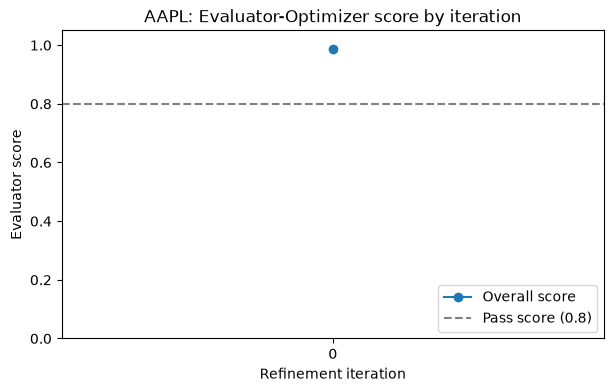

Final version: iteration 0
Final score: 0.988
Accepted: True

## Company

- **Company:** Apple Inc.
- **Sector:** Technology
- **Industry:** Consumer Electronics

## News Analysis

The supplied news assessment characterizes sentiment as **neutral**. It identifies positive and uncertain signals, but the information provided is not enough to establish their overall financial effect.

- **iPhone demand:** Reports said Apple sought **15%–20% cuts to October component orders** for iPhone 18 Pro and Pro Max, citing softer demand and higher memory costs. The supplied information does not quantify any resulting sales or financial impact, confirm the reported order changes, or establish whether demand differed between the two models.
- **App Store:** UBS estimated revenue growth of **5% year over year in September**, compared with no growth in August. Analyst David Vogt cautioned that one month is insufficient to establish a broader trend. The year for these monthly figures is not specified in 

In [51]:
# Score by iteration, followed by the retained version.


# Score by iteration

import matplotlib.pyplot as plt


def plot_evaluation_history(
    result: dict,
    title: str
) -> None:
    """Plot the overall evaluator score for each iteration."""

    history = pd.DataFrame(
        result["history"]
    )

    fig, ax = plt.subplots(
        figsize=(7, 4)
    )

    ax.plot(
        history["iteration"],
        history["overall"],
        marker="o",
        label="Overall score"
    )

    ax.axhline(
        PASS_SCORE,
        linestyle="--",
        color="gray",
        label=f"Pass score ({PASS_SCORE})"
    )

    ax.set_xticks(
        history["iteration"]
    )

    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Refinement iteration")
    ax.set_ylabel("Evaluator score")
    ax.set_title(title)
    ax.legend(loc="lower right")

    plt.show()


plot_evaluation_history(
    review_result,
    f"{review_result['symbol']}: "
    "Evaluator-Optimizer score by iteration"
)


print(
    "Final version: iteration",
    review_result["final_iteration"]
)

print(
    "Final score:",
    review_result["final_score"]
)

print(
    "Accepted:",
    review_result["final_passed"]
)

for issue in review_result.get(
    "final_coverage_issues",
    []
):
    print("Coverage blocker:", issue)

print()
print(
    review_result["final_report"]
)

In [52]:
# Deliberately corrupted draft: invented figures and investment advice.
# Demonstrates rejection and repair. Excluded from agent memory so the
# lesson drawn from it cannot describe a fault the agent did not have.
# Deliberately flawed draft: invented figures and buy advice

flawed_output = dict(research_package)

flawed_output["draft_report"] = (
    research_package["draft_report"]
    + "\n\n"
    + "The company reported EPS of $2.45, beating estimates "
    + "by 24%. Revenue grew 18% year over year. Analysts are "
    + "overwhelmingly bullish after strong product news. "
    + "Investors should buy the stock now."
)

# write_memory=False: this draft was corrupted on purpose, so the lesson
# drawn from it would describe a problem the agent did not actually have.
flawed_result = review_and_refine_report(
    flawed_output,
    write_memory=False
)

pd.DataFrame(
    flawed_result["history"]
)[
    ["iteration"]
    + EVALUATION_CRITERIA
    + [
        "overall",
        "scores_passed",
        "coverage_ok",
        "passed",
    ]
]

,iteration,grounding,completeness,clarity,limitations,overall,scores_passed,coverage_ok,passed
0,0,0.45,0.96,0.82,0.95,0.795,False,True,False
1,1,0.97,1.00,0.98,0.99,0.985,True,True,True


Iteration: 0 | Overall: 0.795 | Passed: False

Issues:
- The final paragraph claims reported EPS was $2.45 and beat estimates by 24%; the supplied earnings analysis instead reports EPS of $2.02, an estimate of $1.89, and a 6.74% beat.
- The claim that revenue grew 18% year over year is unsupported; total revenue and revenue growth are not provided in the supplied analyses.
- The claim that analysts are overwhelmingly bullish is unsupported and conflicts with the supplied UBS Neutral rating; no broader analyst consensus is established.
- The reference to strong product news is unsupported by the supplied analyses, which describe mixed iPhone demand signals and uncertainty.
- The recommendation to buy the stock is portfolio advice and is not supported by the supplied information.
- The final paragraph contradicts the report’s otherwise careful discussion of missing revenue data, uncertainty, and the limits of the analyst rating.

Feedback:
- Delete the final paragraph. If earnings result

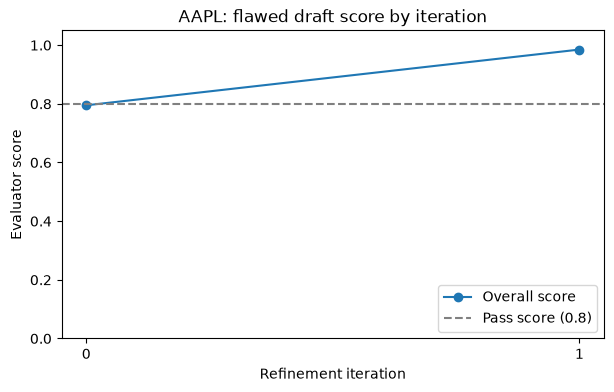

Final version: iteration 1
Final score: 0.985
Accepted: True

## Company

- **Company:** Apple Inc.
- **Sector:** Technology
- **Industry:** Consumer Electronics

## News Analysis

The supplied news assessment characterizes sentiment as **neutral**. It identifies positive and uncertain signals, but the information provided is not enough to establish their overall financial effect.

- **iPhone demand:** Reports said Apple sought **15%–20% cuts to October component orders** for iPhone 18 Pro and Pro Max, citing softer demand and higher memory costs. The supplied information does not quantify any resulting sales or financial impact, confirm the reported order changes, or establish whether demand differed between the two models.
- **App Store:** UBS estimated revenue growth of **5% year over year in September**, compared with no growth in August. Analyst David Vogt cautioned that one month is insufficient to establish a broader trend. The year for these monthly figures is not specified in 

In [53]:
# Reviewer feedback per iteration, the score trajectory, and the
# repaired report.


print_evaluation_feedback(
    flawed_result
)


plot_evaluation_history(
    flawed_result,
    f"{flawed_result['symbol']}: "
    "flawed draft score by iteration"
)


print(
    "Final version: iteration",
    flawed_result["final_iteration"]
)

print(
    "Final score:",
    flawed_result["final_score"]
)

print(
    "Accepted:",
    flawed_result["final_passed"]
)

for issue in flawed_result.get(
    "final_coverage_issues",
    []
):
    print("Coverage blocker:", issue)

print()
print(
    flawed_result["final_report"]
)

# Part 12. Demonstration — Learning Across Runs

Memory is not observable from a single execution, so this part shows the
complete cycle: a record written by the run in Part 11, read back by the
planning step on a fresh run, and the store accumulating across both.

The second step is the substantive one. It calls the planning step directly,
prints the notes that step received, and shows the plan produced in response,
so that the influence of the earlier run on the later plan can be compared
directly.

In [54]:
# Full memory cycle: a record written in Part 11, read back by a fresh
# planning step, and the store accumulating across both runs.
DEMO_SYMBOL = "AAPL"

# 1. The record written by the review run above.
print("=" * 60)
print("1. MEMORY STORE AFTER THE MAIN RUN")
print("=" * 60)

store_now = _read_store().get(
    DEMO_SYMBOL,
    []
)

print(
    json.dumps(
        store_now,
        indent=2,
        default=str
    )
)

# 2. A fresh planning step for the same symbol now reads that record.
print()
print("=" * 60)
print("2. WHAT THE PLANNER READS ON THE NEXT RUN")
print("=" * 60)

replan = node_plan_research({
    "symbol": DEMO_SYMBOL
})

print(replan["memory_context"])

print()
print("Plan produced in response:")

for step in replan["research_plan"]:
    print("-", step)

print()
print("Tools selected :", replan["required_tools"])
print("Agents selected:", replan["required_agents"])

# 3. Record a second completed run to show the store accumulating.
print()
print("=" * 60)
print("3. STORE AFTER A SECOND RECORDED RUN")
print("=" * 60)

second_run = review_and_refine_report(
    research_package
)

print(
    "New lesson:",
    second_run["memory_record"]["lesson"]
)

print()

for entry in _read_store().get(
    DEMO_SYMBOL,
    []
):
    print(
        "-",
        entry["timestamp"],
        "| score",
        entry["evaluator_score"],
        "| articles",
        entry["article_count"],
        "|",
        entry["lesson"][:90]
    )

print()
print(
    "Records retained for",
    DEMO_SYMBOL,
    ":",
    len(
        _read_store().get(
            DEMO_SYMBOL,
            []
        )
    ),
    "(capped at",
    MEMORY_KEEP,
    ")"
)

print(
    "Lesson length limit:",
    MAX_LESSON_CHARS,
    "characters, enforced by the RunLesson schema."
)

print()
print(
    "Note: in Colab,", MEMORY_PATH,
    "does not survive a runtime restart."
)
print(
    "Commit it to the repository or write it to "
    "mounted Drive to persist across sessions."
)

1. MEMORY STORE AFTER THE MAIN RUN
[
  {
    "timestamp": "2026-10-10T23:53:10+00:00",
    "price": 336.64,
    "price_change_30d_pct": 3.08,
    "category": "market_news",
    "sentiment": "neutral",
    "article_count": 5,
    "evaluator_score": 0.975,
    "accepted": true,
    "lesson": "Next run should verify Munster\u2019s Pro-versus-Pro Max demand clue to the split cycle and note that 30-day market data lacks the within-period price path."
  },
  {
    "timestamp": "2026-10-10T23:53:58+00:00",
    "price": 336.64,
    "price_change_30d_pct": 3.08,
    "category": "market_news",
    "sentiment": "neutral",
    "article_count": 5,
    "evaluator_score": 0.96,
    "accepted": true,
    "lesson": "Include Munster\u2019s point that demand differences between iPhone models may signal consumer response, and clarify that 30-day data omits intraperiod prices and daily moves."
  },
  {
    "timestamp": "2026-10-11T00:26:25+00:00",
    "price": 336.64,
    "price_change_30d_pct": 3.08,
    

- [2026-10-10T23:53:10+00:00] price 336.64, 30-day change 3.08%, category market_news, sentiment neutral, 5 articles, evaluator score 0.975. Lesson: Next run should verify Munster’s Pro-versus-Pro Max demand clue to the split cycle and note that 30-day market data lacks the within-period price path.
- [2026-10-10T23:53:58+00:00] price 336.64, 30-day change 3.08%, category market_news, sentiment neutral, 5 articles, evaluator score 0.96. Lesson: Include Munster’s point that demand differences between iPhone models may signal consumer response, and clarify that 30-day data omits intraperiod prices and daily moves.
- [2026-10-11T00:26:25+00:00] price 336.64, 30-day change 3.08%, category analyst_opinion, sentiment neutral, 5 articles, evaluator score 0.99. Lesson: When citing Gene Munster’s commentary, verify and include the underlying publication and date; distinguish missing source details from the already identified commentator.
- [2026-10-11T00:26:46+00:00] price 336.64, 30-day change

New lesson: Keep the successful workflow, while checking that future runs have enough recent, independent sources to corroborate key AAPL developments.

- 2026-10-10T23:53:58+00:00 | score 0.96 | articles 5 | Include Munster’s point that demand differences between iPhone models may signal consumer 
- 2026-10-11T00:26:25+00:00 | score 0.99 | articles 5 | When citing Gene Munster’s commentary, verify and include the underlying publication and d
- 2026-10-11T00:26:46+00:00 | score 0.995 | articles 5 | Maintain the current research process, while checking that news sources are current and co
- 2026-10-11T00:49:11+00:00 | score 0.988 | articles 5 | Keep the current research approach, while checking article timestamps and corroborating ke
- 2026-10-11T00:49:53+00:00 | score 0.995 | articles 5 | Keep the successful workflow, while checking that future runs have enough recent, independ

Records retained for AAPL : 5 (capped at 5 )
Lesson length limit: 200 characters, enforced by the RunLesson 

# Part 13. Conclusion

## 13.1 Summary

The notebook implements an autonomous Investment Research Agent incorporating
the three required workflow patterns — prompt chaining, routing, and
evaluator–optimiser — together with the four autonomous agent functions:
planning, dynamic tool use, self-reflection, and learning across runs. The
pipeline executes from end to end without error, and each pattern and function
is exercised by a test whose output is retained in this notebook.

## 13.2 Observations

**Agent reliability is bounded by the stability of its data sources.** During
development the Yahoo Finance quote news endpoint began returning an empty list
for every symbol while remaining available and raising no error. The news stage
consequently received nothing, and the resulting reports contained an empty
News Analysis section. Retrieval was restructured to attempt three endpoints in
sequence. The broader observation is that an agent whose tools fail silently
degrades without signalling that it has degraded.

**Plausible-looking output can be produced from no data at all.** Before the
coverage check was introduced, reports whose News Analysis consisted entirely
of statements that no articles were available received evaluator scores between
0.95 and 0.99 and were accepted. The evaluation criteria rewarded candour about
missing information, and an empty report satisfies that criterion more easily
than a substantive one, because it presents less material to criticise. Scores
therefore rose as content fell. Language-model scoring of this kind measures
the qualities it is asked about and nothing else, and requires pairing with
independent checks on whether the inputs arrived.

**Defects upstream of the reasoning layer are difficult to detect from the
output.** Earnings records were retrieved by selecting the first row of a
table sorted with the most recent date first. That table includes quarters
that have not yet occurred, which carry an estimate but no reported result.
The selection therefore returned an unreported future quarter on every run,
and the earnings specialist correctly reported that no results were available.
The code raised no error and the report was internally consistent; only
comparison against the source table revealed the fault.

**Prompts that share a task must share the same permitted evidence.** When the
report-drafting step was given company reference data that the evaluation step
was not, the evaluator identified the resulting sector and industry statements
as unsupported and recommended their removal. Extending an agent's evidence in
one component requires extending it in every component that judges or revises
that output.

**Absence of control flow on the failure path is not neutral.** The second
stage originally advanced unconditionally after retrieval. An invalid symbol
therefore produced a complete five-section research report describing a company
that does not exist, consuming approximately seven model calls to do so. The
first stage had guarded every step against exactly this condition; the second
stage had not.

**Autonomy is only meaningful where the decision has an effect.** The planning
component selects which tools to call, and across repeated runs the
supplementary retrieval tools it selected contributed no fields that the main
pipeline had not already supplied. The selection consumed requests without
influencing the result. Similarly, the specialists named in the plan are not
used to determine which specialists run.

**Constraints requested in a prompt are not constraints.** An earlier
implementation of run memory asked the model for a single sentence of under
forty words and received multi-paragraph responses with headings. Enforcing the
limit through a schema and truncating on write produced consistently brief
records.

**Repeated scoring of equivalent material is not stable.** Three reports of
substantively identical content received overall scores of 0.95, 0.982 and
0.988 across separate runs. A fixed numeric acceptance threshold applied to
such scores is therefore sensitive to variation unrelated to report quality.

## 13.3 Future improvements

**Control flow.** The specialists named in the research plan should determine
which specialists execute, through conditional dispatch rather than a fixed
sequence. This would make the planning decision consequential and would also
remove the need for the separate demonstration routing graph, since routing
would occur within the main pipeline.

**Earlier failure detection.** The input-coverage check currently runs in the
third stage, by which point the second stage has already completed. Applying
the same check immediately after retrieval would avoid the intervening model
calls.

**Caching.** Each run retrieves data from Yahoo Finance without reference to
previous retrievals, and the tests repeat requests for the same symbols. A
response cache keyed by symbol and request type would reduce both latency and
exposure to rate limiting.

**Stricter coverage thresholds.** The present requirement of a single article
is weak relative to the five requested. Requiring a larger proportion, and
adding a corresponding check that earnings figures represent a reported rather
than a forthcoming quarter, would make the coverage test more meaningful.

**Reconciliation of the two quality signals.** The self-assessment produced in
the second stage and the independent evaluation produced in the third scored
the same drafts as much as 0.37 apart, and neither value influences the other.
Either the self-assessment should gate entry to evaluation or the two should be
combined into a single reported measure.

**Separation of memory by scope.** Records are presently keyed by symbol, so an
observation about research method learned on one company is unavailable when
analysing another. Methodological notes could be held in a separate store
retrieved by semantic similarity, while the per-symbol store continues to
provide a numerical baseline for detecting change between runs.

**Durable memory.** The memory file does not survive a Colab runtime restart.
Committing it to the project repository, writing it to mounted storage, or
moving it to a small database would allow learning to accumulate across
sessions rather than within one.

**Calibration of the evaluator.** Reports now pass on the first iteration with
no issues raised, so the refinement loop is exercised only by the deliberately
corrupted draft. A set of reports with known defects would allow the reviewer's
thresholds and criteria to be calibrated against expected outcomes.

**Unified execution.** The three stages are presently separate graphs joined by
intermediate variables. Composing them into a single graph would allow the
complete pipeline to be invoked once per symbol and would make the data
contracts between stages enforceable in one place.

**Correct handling of reporting dates.** Earnings dates carry timezone
information while the comparison date does not, so the two can disagree by a
day around a reporting date. A timezone-aware comparison would remove this
edge case.

**Evaluation at scale.** Results are reported for a small number of large,
widely covered technology companies. Extending the tests to smaller companies,
other sectors and symbols with sparse news coverage would establish how far the
present behaviour generalises.

# Contributions

| Contributor | Area of responsibility | Components |
| --- | --- | --- |
| **Ahmed Eldahmy** | Data acquisition, external interfaces, and prompt chaining | Market and news retrieval with retry and fallback handling (Parts 2 and 3); the five-step prompt-chaining workflow and its output schemas (Part 4); the stage-one output contract, tool registration and verification suite (Part 5) |
| **Brian Covington** | Research agent, planning, tool use, and routing | Research planning and dynamic tool selection (Part 7); the news, earnings and market specialists (Part 8); report synthesis and self-reflection (Part 9); workflow assembly, the conditional routing graph, and routing verification (Part 10) |
| **Sai Gautham Bandi** | Evaluation, refinement, and run memory | The evaluation schema and scoring thresholds, the reviewer and optimiser components, and the refinement loop with best-version retention (Part 11); the agent memory store and its integration with planning (Parts 6 and 12) |

Project repository: https://github.com/Ahmedeldahmy/AAI-520-Multi-Agent-Financial-Analysis